In [1]:
from __future__ import annotations
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import logging
import os
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# Suppress the deprecated silent downcast warning in .replace().
# We handle the behavior explicitly in Cell 12 with .infer_objects().
pd.set_option("future.no_silent_downcasting", True)
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")

import sys
import subprocess
import platform

import contextlib
import io

DATASET_SLUG = "joebeachcapital/world-happiness-report-2013-2023"
CSV_PATTERN = "World Happiness Report*.csv"
MIN_EXPECTED_CSVS = 10
REQUIRED_YEARS = {2013, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023}
MISSING_THRESHOLD = 0.10   # max fraction of NaN allowed in a core column
MAX_RESIDUAL = 4           # max residual NaN allowed in a core column per country
MIN_COUNTRIES_SUBREGION = 7
MIN_COUNTRIES_CORRELATION = 15
TOP_N_SUBREGION = 4
BOTTOM_N_SUBREGION = 4
TOP_N_CONTINENT = 20
BOTTOM_N_CONTINENT = 20
TOP_N_AMERICAS = 13
BOTTOM_N_AMERICAS = 13
FIGURES_DIR = Path("./docs/figures").resolve()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DOCS_DIR = Path("./docs/tables").resolve()
DOCS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Figures will be saved to: ./docs/figures")
print(f"Tables will be saved to:  ./docs/tables")

data_dir = Path(os.getenv("HAPPINESS_DATA_DIR", "./docs/data")).expanduser().resolve()
data_dir.mkdir(parents=True, exist_ok=True)
print(f"Data directory: ./docs/data")

Figures will be saved to: ./docs/figures
Tables will be saved to:  ./docs/tables
Data directory: ./docs/data


In [2]:
# ---------------------------------------------------------------
# Cell 2 - Dataset acquisition with explicit year validation
#
# We validate by REQUIRED_YEARS instead of a raw file count so that
# the pipeline fails early with a clear message if a specific year
# is missing, instead of crashing later with KeyError in Cell 7/8/9.
# ---------------------------------------------------------------

def _years_from_paths(paths: list[Path]) -> set[int]:
    return {int(p.stem.rsplit(" ", 1)[-1]) for p in paths}


existing_csvs = sorted(data_dir.glob(CSV_PATTERN))
available_years = _years_from_paths(existing_csvs)
missing = REQUIRED_YEARS - available_years

if missing:
    logging.info("Missing years %s; downloading dataset.", sorted(missing))
    with contextlib.redirect_stdout(io.StringIO()), \
         contextlib.redirect_stderr(io.StringIO()):
        kagglehub.dataset_download(DATASET_SLUG, output_dir=str(data_dir))
    existing_csvs = sorted(data_dir.glob(CSV_PATTERN))
    available_years = _years_from_paths(existing_csvs)
    missing = REQUIRED_YEARS - available_years

if missing:
    raise FileNotFoundError(
        f"After download, still missing years: {sorted(missing)}. "
        f"Found: {sorted(available_years)}."
    )

unexpected = available_years - REQUIRED_YEARS
if unexpected:
    logging.warning("Unexpected years (will be ignored): %s", sorted(unexpected))

print(f"CSV files ready: {len(existing_csvs)}")
print(f"Required years present: {sorted(available_years & REQUIRED_YEARS)}")

INFO | Missing years [2013, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]; downloading dataset.


Extracting files...
CSV files ready: 10
Required years present: [2013, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


In [3]:
# Cell 3 — Load yearly reports into a dict {year: DataFrame}
reports = {}
for csv_path in existing_csvs:
    year = int(csv_path.stem.rsplit(" ", 1)[-1])
    reports[year] = pd.read_csv(csv_path)

print(f"Years loaded: {sorted(reports)}")

Years loaded: [2013, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


In [4]:
# Cell 4 — Exploratory overview
all_columns = sorted({c for df in reports.values() for c in df.columns})

print(f"Yearly files: {len(reports)}")
print(f"Union of columns across all years: {len(all_columns)}\n")

for year, df in sorted(reports.items()):
    print(f"Year {year} — shape={df.shape}")
    print(f"  Columns ({len(df.columns)}): {sorted(df.columns.tolist())}")

print("\nAll unique column names:")
for col in all_columns:
    print(f"  - {col}")

reports[2013].head(3)

Yearly files: 10
Union of columns across all years: 58

Year 2013 — shape=(156, 13)
  Columns (13): ['Corruption', 'Country', 'Donation', 'Freedom', 'GDP per capita', 'Generosity', 'Happiness (Yesterday)', 'Healthy life expectancy', 'Ladder', 'Negative Affect', 'Positive Affect', 'Region', 'Social Support']
Year 2015 — shape=(158, 12)
  Columns (12): ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Generosity', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Region', 'Standard Error', 'Trust (Government Corruption)']
Year 2016 — shape=(157, 13)
  Columns (13): ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Generosity', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Lower Confidence Interval', 'Region', 'Trust (Government Corruption)', 'Upper Confidence Interval']
Year 2017 — shape=(155, 12)
  Columns (12): ['Country', 'Dystopia.Residual', 'Economy..GDP.per.Capita.', 'Family', 'Fre

,Country,Region,Ladder,Social Support,Freedom,Corruption,Donation,Generosity,Positive Affect,Negative Affect,Happiness (Yesterday),GDP per capita,Healthy life expectancy
0,Afghanistan,4,4.040,0.525,0.540,0.755,0.348,0.207,0.663,0.270,0.721,979.0,36.535
1,Albania,1,5.550,0.759,0.553,0.827,0.112,-0.192,0.627,0.276,0.568,7652.0,61.417
2,Algeria,8,5.422,0.831,0.551,0.681,0.106,-0.194,0.567,0.245,0.542,7547.0,61.722


In [5]:
# ---------------------------------------------------------------
# Cell 5 - Standardization of column names
#
# Different yearly reports use different names for the same concept
# (e.g. "Happiness Score", "Ladder score", "Score" -> "Happiness").
# Below is a single alias -> canonical mapping that unifies them all.
#
# Note: some years ship BOTH a raw column and its "Explained by:"
# normalized version. When that happens we keep the normalized one,
# matching the original analysis. In this dataset the situation does
# not actually occur, but the guard keeps the code defensive.
# ---------------------------------------------------------------

COLUMN_MAP = {
    "Country":                   ["Country", "Country name", "Country or region"],
    "Region":                    ["Region", "Regional indicator"],
    "Happiness":                 ["Happiness", "Happiness Score", "Happiness score",
                                  "Happiness.Score", "Ladder score", "Score", "Ladder"],
    "Happiness Rank":            ["Happiness Rank", "Happiness.Rank", "RANK", "Overall rank"],
    "GDP per capita":            ["GDP per capita", "Economy (GDP per Capita)",
                                  "Economy..GDP.per.Capita", "Economy..GDP.per.Capita.",
                                  "Explained by: GDP per capita"],
    "Logged GDP per capita":     ["Logged GDP per capita", "Logged GDP per Capita",
                                  "Explained by: Log GDP per capita"],
    "Life Expectancy":           ["Life Expectancy", "Health (Life Expectancy)",
                                  "Health..Life.Expectancy.", "Healthy life expectancy",
                                  "Explained by: Healthy life expectancy"],
    "Freedom":                   ["Freedom", "Freedom to make life choices",
                                  "Explained by: Freedom to make life choices"],
    "Social Support":            ["Social Support", "Social support", "Family",
                                  "Explained by: Social support"],
    "Generosity":                ["Generosity", "Explained by: Generosity"],
    "Corruption":                ["Corruption", "Perceptions of corruption",
                                  "Trust..Government.Corruption",
                                  "Trust (Government Corruption)",
                                  "Trust..Government.Corruption.",
                                  "Explained by: Perceptions of corruption"],
    "Dystopia + residual":       ["Dystopia + residual", "Dystopia (1.83) + residual",
                                  "Dystopia.Residual", "Dystopia Residual"],
    "Ladder score in Dystopia":  ["Ladder score in Dystopia"],
    "Standard error":            ["Standard error", "Standard error of ladder score",
                                  "Standard Error"],
    "Upper Confidence Interval": ["Upper Confidence Interval", "Whisker-high",
                                  "Whisker.high", "upperwhisker"],
    "Lower Confidence Interval": ["Lower Confidence Interval", "Whisker-low",
                                  "Whisker.low", "lowerwhisker"],
}

ALIAS_TO_CANONICAL = {a: c for c, aliases in COLUMN_MAP.items() for a in aliases}
NORMALIZED_PREFIX = "Explained by:"

for year in list(reports):
    df = reports[year].copy()
    df["Year"] = year  # keep the year as a column for later concatenation

    # (1) If BOTH a raw and its "Explained by:" version exist for the same
    #     concept, drop the raw one (keep the normalized version).
    drop_raw = []
    for aliases in COLUMN_MAP.values():
        normalized = [a for a in aliases if a.startswith(NORMALIZED_PREFIX)]
        raw = [a for a in aliases if not a.startswith(NORMALIZED_PREFIX)]
        if any(a in df.columns for a in normalized) and any(a in df.columns for a in raw):
            drop_raw += [a for a in raw if a in df.columns]
    if drop_raw:
        logging.info("Year %d: dropping raw duplicates %s", year, drop_raw)
        df = df.drop(columns=drop_raw)

    # (2) Rename every known alias to its canonical name.
    df = df.rename(columns=ALIAS_TO_CANONICAL)

    # (3) Defensive: no canonical name should appear twice after renaming.
    if df.columns.duplicated().any():
        dupes = df.columns[df.columns.duplicated()].tolist()
        logging.warning("Year %d: colliding canonical columns %s (keeping first)",
                        year, dupes)
        df = df.loc[:, ~df.columns.duplicated()]

    reports[year] = df

print(f"Standardized {len(reports)} yearly DataFrames.")

INFO | Year 2020: dropping raw duplicates ['Logged GDP per capita', 'Healthy life expectancy', 'Freedom to make life choices', 'Social support', 'Generosity', 'Perceptions of corruption']
INFO | Year 2021: dropping raw duplicates ['Logged GDP per capita', 'Healthy life expectancy', 'Freedom to make life choices', 'Social support', 'Generosity', 'Perceptions of corruption']
INFO | Year 2023: dropping raw duplicates ['Logged GDP per capita', 'Healthy life expectancy', 'Freedom to make life choices', 'Social support', 'Generosity', 'Perceptions of corruption']


Standardized 10 yearly DataFrames.


In [6]:
# ---------------------------------------------------------------
# Cell 6 - Align columns across years
#
# After renaming, some years miss columns that others have. We reindex
# every year to the same ordered set: missing columns become NaN and
# are dropped later ONLY if they turn out to be entirely empty.
# ---------------------------------------------------------------

COLUMN_ORDER = [
    "Year", "Country", "Region", "Happiness", "Happiness Rank",
    "GDP per capita", "Logged GDP per capita", "Life Expectancy",
    "Freedom", "Social Support", "Generosity", "Donation",
    "Corruption", "Dystopia + residual", "Ladder score in Dystopia",
    "Happiness (Yesterday)", "Upper Confidence Interval",
    "Lower Confidence Interval", "Positive Affect", "Negative Affect",
    "Standard error",
]

for year, df in reports.items():
    # Any column not listed above is appended at the end (no data loss).
    extra = [c for c in df.columns if c not in COLUMN_ORDER]
    reports[year] = df.reindex(columns=COLUMN_ORDER + extra)

print(f"Columns per year: {len(reports[2013].columns)}")
print(list(reports[2013].columns))

Columns per year: 21
['Year', 'Country', 'Region', 'Happiness', 'Happiness Rank', 'GDP per capita', 'Logged GDP per capita', 'Life Expectancy', 'Freedom', 'Social Support', 'Generosity', 'Donation', 'Corruption', 'Dystopia + residual', 'Ladder score in Dystopia', 'Happiness (Yesterday)', 'Upper Confidence Interval', 'Lower Confidence Interval', 'Positive Affect', 'Negative Affect', 'Standard error']


In [7]:
# ---------------------------------------------------------------
# Cell 7 - Anomalies in 2013
#
# Observed issues:
#   * GDP per capita and Life Expectancy are on a much larger scale in
#     2013 than in other years -> normalize both to [0, 1].
#   * Corruption is inverted in 2013 -> flip with 1 - x so that "higher
#     is better" matches the rest of the years.
# ---------------------------------------------------------------

df2013 = reports[2013].copy()

gdp_min, gdp_max = df2013["GDP per capita"].min(), df2013["GDP per capita"].max()
df2013["GDP per capita"] = (df2013["GDP per capita"] - gdp_min) / (gdp_max - gdp_min)

le_min, le_max = df2013["Life Expectancy"].min(), df2013["Life Expectancy"].max()
df2013["Life Expectancy"] = (df2013["Life Expectancy"] - le_min) / (le_max - le_min)

df2013["Corruption"] = 1 - df2013["Corruption"]

reports[2013] = df2013

print(f"GDP per capita range:       [{df2013['GDP per capita'].min():.3f}, "
      f"{df2013['GDP per capita'].max():.3f}]")
print(f"Life Expectancy range:      [{df2013['Life Expectancy'].min():.3f}, "
      f"{df2013['Life Expectancy'].max():.3f}]")
print(f"Corruption range:           [{df2013['Corruption'].min():.3f}, "
      f"{df2013['Corruption'].max():.3f}]")

GDP per capita range:       [0.000, 1.000]
Life Expectancy range:      [0.000, 1.000]
Corruption range:           [0.034, 0.925]


In [8]:
# ---------------------------------------------------------------
# Cell 8 - Per-year Corruption normalization
#
# The raw WHR Corruption data is on different scales across years:
#   2013: "Trust (Government Corruption)" - after the 1-x fix in
#         Cell 7, range ~0.03-0.92, mean ~0.25
#   2015+: "Perceptions of corruption" - range ~0.00-0.55, mean ~0.13
#
# Direction is now consistent (higher = less corrupt) thanks to Cell 7,
# but the SCALE differs. To make years comparable we MinMax-normalize
# Corruption WITHIN each year to [0, 1].
#
# Trade-off (documented in the report): every year is rescaled to
# [0,1], so min=0 and max=1 by construction. The mean stays around
# 0.24-0.27 across years because the underlying distribution is
# right-skewed (most countries cluster at the low-corruption end).
# What we gain is comparability: a value of 0.7 means "relatively
# uncorrupt for that year" in every year. What we lose is absolute
# level: cross-year level comparisons are no longer meaningful.
#
# 2014 is created AFTER this cell (Cell 9) as the average of the
# already-normalized 2013 and 2015 values, which preserves the
# "2014 = interpolation of 2013 and 2015" interpretation.
# ---------------------------------------------------------------

for year in list(reports):
    if year == 2014:
        continue  # 2014 does not exist yet at this point

    col = reports[year]["Corruption"]
    mn, mx = col.min(), col.max()

    if mx > mn:
        reports[year]["Corruption"] = (col - mn) / (mx - mn)
    else:
        logging.warning(
            "Year %d: Corruption is constant (min == max); skipping MinMax.",
            year,
        )

print("Corruption range per year after per-year normalization:")
for year in sorted(reports):
    c = reports[year]["Corruption"]
    print(f"  {year}: min={c.min():.3f}, max={c.max():.3f}, mean={c.mean():.3f}")

Corruption range per year after per-year normalization:
  2013: min=0.000, max=1.000, mean=0.245
  2015: min=0.000, max=1.000, mean=0.260
  2016: min=0.000, max=1.000, mean=0.272
  2017: min=0.000, max=1.000, mean=0.265
  2018: min=0.000, max=1.000, mean=0.245
  2019: min=0.000, max=1.000, mean=0.244
  2020: min=0.000, max=1.000, mean=0.245
  2021: min=0.000, max=1.000, mean=0.247
  2022: min=0.000, max=1.000, mean=0.264
  2023: min=0.000, max=1.000, mean=0.260


In [9]:
# ---------------------------------------------------------------
# Cell 9 - Missing year 2014
#
# The dataset has no 2014 CSV. We reconstruct it as the year-by-year
# average of 2013 and 2015, matched by COUNTRY (not by row position),
# so the merge stays correct even if the country order differs between
# the two frames. Only countries present in both years are kept.
#
# Corruption needs special treatment: 2014 Corruption is the average
# of two ALREADY NORMALIZED values (2013 and 2015, both in [0,1] from
# Cell 8). The average lands strictly inside [0,1] but does not touch
# the boundaries, because the least-corrupt country in 2013 is not
# necessarily the same as in 2015. We re-normalize 2014 Corruption to
# [0,1] here so every year satisfies min=0, max=1 (Sanity 2).
#
# Re-normalizing is a monotone transformation: it preserves the
# relative ordering of countries WITHIN 2014, only the scale is
# adjusted. Semantics: 2014 Corruption = "average relative position
# across 2013 and 2015", mapped to [0,1] for consistency.
#
# Note: Happiness Rank is NOT reconstructed. It was computed per-year
# on a different country composition, so the original ranking no
# longer means what it did in the source report (see Cell 13). New
# ordinal variables come from Cell 18 (quantile classification).
# ---------------------------------------------------------------

NUMERIC_COLS = [
    "Happiness", "GDP per capita", "Logged GDP per capita",
    "Life Expectancy", "Freedom", "Social Support", "Generosity",
    "Corruption", "Dystopia + residual", "Standard error",
    "Upper Confidence Interval", "Lower Confidence Interval",
]
common_numeric = [c for c in NUMERIC_COLS
                  if c in reports[2013].columns and c in reports[2015].columns]

avg = pd.merge(
    reports[2013][["Country", "Region", *common_numeric]],
    reports[2015][["Country", *common_numeric]],
    on="Country",
    suffixes=("_2013", "_2015"),
    how="inner",
)

df2014 = pd.DataFrame({"Country": avg["Country"], "Region": avg["Region"]})
for col in common_numeric:
    df2014[col] = (avg[f"{col}_2013"] + avg[f"{col}_2015"]) / 2
df2014["Year"] = 2014

# Re-normalize 2014 Corruption to [0,1] (see docstring above).
corr = df2014["Corruption"]
mn, mx = corr.min(), corr.max()
if mx > mn:
    df2014["Corruption"] = (corr - mn) / (mx - mn)
    logging.info(
        "2014 Corruption re-normalized: [%.4f, %.4f] -> [0.0000, 1.0000]",
        mn, mx,
    )
else:
    logging.warning("2014 Corruption is constant; skipping re-normalization.")

# Realign to the same column set used by the other years.
df2014 = df2014.reindex(columns=reports[2013].columns)
reports[2014] = df2014

# Keep the dict in chronological order for the concatenation step.
reports = dict(sorted(reports.items()))

print(f"Years in dict: {sorted(reports)}")
print(f"2014 shape:    {reports[2014].shape}")
print(f"2014 Corruption range: [{reports[2014]['Corruption'].min():.4f}, "
      f"{reports[2014]['Corruption'].max():.4f}]")
print(reports[2014].head(3).to_string(index=False))

INFO | 2014 Corruption re-normalized: [0.0017, 0.9776] -> [0.0000, 1.0000]


Years in dict: [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
2014 shape:    (154, 21)
2014 Corruption range: [0.0000, 1.0000]
 Year     Country  Region  Happiness  Happiness Rank  GDP per capita  Logged GDP per capita  Life Expectancy  Freedom  Social Support  Generosity  Donation  Corruption  Dystopia + residual  Ladder score in Dystopia  Happiness (Yesterday)  Upper Confidence Interval  Lower Confidence Interval  Positive Affect  Negative Affect  Standard error
 2014 Afghanistan       4     3.8075             NaN        0.166208                    NaN         0.227678 0.387070        0.413925     0.28605       NaN    0.209835                  NaN                       NaN                    NaN                        NaN                        NaN              NaN              NaN             NaN
 2014     Albania       1     5.2545             NaN        0.491445                    NaN         0.755948 0.455165        0.781670    -0.02464       NaN    0.137741  

In [10]:
# ---------------------------------------------------------------
# Cell 10 - GDP per capita missing in 2020, 2021, 2023
#
# Those years only ship the log-transformed GDP. We invert the log with
# np.exp before filling, so the units stay comparable with the rest of
# the panel (otherwise the log-dominated values would skew the
# MinMaxScaler applied later).
# ---------------------------------------------------------------

for year in (2020, 2021, 2023):
    df = reports[year].copy()
    mask = df["GDP per capita"].isna() & df["Logged GDP per capita"].notna()
    df.loc[mask, "GDP per capita"] = np.exp(df.loc[mask, "Logged GDP per capita"])
    reports[year] = df
    print(f"Year {year}: filled {int(mask.sum())} GDP values via np.exp(Logged GDP)")

# Sanity check: no NaN left in the GDP column for those years.
for year in (2020, 2021, 2023):
    n_missing = reports[year]["GDP per capita"].isna().sum()
    print(f"Year {year}: {n_missing} remaining NaN in GDP per capita")

Year 2020: filled 153 GDP values via np.exp(Logged GDP)
Year 2021: filled 149 GDP values via np.exp(Logged GDP)
Year 2023: filled 137 GDP values via np.exp(Logged GDP)
Year 2020: 0 remaining NaN in GDP per capita
Year 2021: 0 remaining NaN in GDP per capita
Year 2023: 0 remaining NaN in GDP per capita


In [11]:
# ---------------------------------------------------------------
# Cell 11 - Country name standardization
#
# Different yearly reports use slightly different names for the same
# country (e.g. "Turkey" vs "Turkiye", "Hong Kong S.A.R. of China" vs
# "Hong Kong", "Congo (Kinshasa)" vs "R.D.Congo"). We normalize them
# here so that later groupby / merge operations align correctly.
#
# Note: "Congo (Brazzaville)" and "Congo (Kinshasa)" are two distinct
# countries; they are mapped to "Congo" and "R.D.Congo" respectively
# to avoid collapsing them into a single entity.
# ---------------------------------------------------------------

COUNTRY_MAP = {
    "Azerbaijan*": "Azerbaijan",
    "Belarus*": "Belarus",
    "Botswana*": "Botswana",
    "Chad*": "Chad",
    "Comoros*": "Comoros",
    "Congo (Brazzaville)": "Congo",
    "Congo (Kinshasa)": "R.D.Congo",
    "Czechia":"Czech Republic",
    "Eswatini, Kingdom of*": "Eswatini",
    "Swaziland": "Eswatini",
    "Gambia*": "Gambia",
    "Guatemala*": "Guatemala",
    "Hong Kong S.A.R. of China": "Hong Kong",
    "Hong Kong S.A.R., China": "Hong Kong",
    "Kuwait*": "Kuwait",
    "Lesotho*": "Lesotho",
    "Liberia*": "Liberia",
    "Libya*": "Libya",
    "Luxembourg*": "Luxembourg",
    "Madagascar*": "Madagascar",
    "Mauritania*": "Mauritania",
    "Niger*": "Niger",
    "North Cyprus*": "North Cyprus",
    "Northern Cyprus": "North Cyprus",
    "Macedonia": "North Macedonia",
    "Palestinian Territories": "Palestine",
    "Palestinian Territories*": "Palestine",
    "State of Palestine": "Palestine",
    "Rwanda*": "Rwanda",
    "Somaliland Region": "Somaliland",
    "Somaliland region": "Somaliland",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Turkey": "Turkiye",
    "Turkmenistan*": "Turkmenistan",
    "Yemen*": "Yemen",
}

for year in list(reports):
    reports[year] = reports[year].assign(
        Country=reports[year]["Country"].replace(COUNTRY_MAP)
    )

print(f"Countries standardized across {len(reports)} years.")

Countries standardized across 11 years.


In [12]:
# ---------------------------------------------------------------
# Cell Diagnostic: 2015 as source of truth for regions
#
# READ-ONLY. Does not modify `reports`.
#
# Approach:
#   1. Deep-copy `reports` so the original is untouched.
#   2. Use the 2015 DataFrame as the canonical source for regions.
#   3. In every OTHER year, drop the current Region and re-attach
#      the 2015 region via a Country -> Region map.
#   4. Report countries that end up without a region (those that
#      exist in some year but not in 2015).
#
# The output tells us whether 2015 covers the whole panel or if
# manual assignments are needed for the few remaining countries.
# ---------------------------------------------------------------

diagnostic = {year: df.copy() for year, df in reports.items()}

# 2015 as source of truth
source_2015 = (
    diagnostic[2015][["Country", "Region"]]
    .dropna(subset=["Region"])
    .drop_duplicates("Country")
)
region_2015 = source_2015.set_index("Country")["Region"]

print(f"Source: 2015 — {len(region_2015)} countries with a region\n")

all_missing: dict[str, list[int]] = {}

for year in sorted(diagnostic):
    if year == 2015:
        continue
    df = diagnostic[year]
    df["Region"] = df["Country"].map(region_2015)

    missing = sorted(df.loc[df["Region"].isna(), "Country"].unique().tolist())
    n_total = df["Country"].nunique()
    n_missing = len(missing)

    if n_missing == 0:
        print(f"Year {year}: {n_total} countries — OK (0 missing)")
    else:
        print(f"Year {year}: {n_total} countries — {n_missing} MISSING")
        for country in missing:
            all_missing.setdefault(country, []).append(year)

print()
if all_missing:
    print(f"{len(all_missing)} countries missing a region in at least one year:")
    for country in sorted(all_missing):
        print(f"  {country:<30} -> missing in years {all_missing[country]}")
    print("\nThese countries need a manual region assignment.")
else:
    print("No country missing a region in any year.")
    print("2015 covers the whole panel — safe to use as source of truth.")

Source: 2015 — 158 countries with a region

Year 2013: 156 countries — OK (0 missing)
Year 2014: 154 countries — OK (0 missing)
Year 2016: 157 countries — 5 MISSING
Year 2017: 155 countries — 4 MISSING
Year 2018: 156 countries — 4 MISSING
Year 2019: 156 countries — 4 MISSING
Year 2020: 153 countries — 4 MISSING
Year 2021: 149 countries — 3 MISSING
Year 2022: 146 countries — 2 MISSING
Year 2023: 137 countries — 2 MISSING

7 countries missing a region in at least one year:
  Belize                         -> missing in years [2016, 2017, 2018]
  Gambia                         -> missing in years [2019, 2020, 2021, 2022, 2023]
  Maldives                       -> missing in years [2020, 2021]
  Namibia                        -> missing in years [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
  Puerto Rico                    -> missing in years [2016]
  Somalia                        -> missing in years [2016, 2017, 2018, 2019]
  South Sudan                    -> missing in years [2016, 20

In [13]:
# ---------------------------------------------------------------
# Cell 12 - Region and Subregion standardization (replacement)
#
# Produces three columns:
#   WHR_Region : original 10-value WHR taxonomy (audit trail only)
#   Subregion  : 11-value taxonomy (WHR-derived; NA-ANZ split into
#                North America / Australia and New Zealand; MENA split
#                into Middle East / North Africa; CIS merged into
#                Central and Eastern Europe)
#   Region     : 4-value continent taxonomy
#                (Africa, Americas, Asia, Europe)
#
# 2015 is used as the source of truth for Subregion, matching the
# original project's approach (the 2015 CSV is the most complete
# single-year source). Countries not in 2015 receive a manual
# assignment.
#
# Australia and New Zealand are assigned to Continent = Asia
# (UNESCAP "Asia-Pacific" convention, documented in the report).
# Turkey and the Caucasian/Central Asian former Soviet states are
# assigned to Europe (documented exception; see report methodology).
# ---------------------------------------------------------------

# (1) Standardize the raw WHR region (numeric codes + string variants)
REGION_MAP = {
    # numeric codes (0-9, present in at least one yearly CSV)
    0: "Western Europe",
    1: "Central and Eastern Europe",
    2: "Commonwealth of Independent States",
    3: "Southeast Asia",
    4: "South Asia",
    5: "East Asia",
    6: "Latin America and Caribbean",
    7: "North America and Australia and New Zealand",
    8: "Middle East and Northern Africa",
    9: "Sub-Saharan Africa",
    # string variants
    "Southeastern Asia": "Southeast Asia",
    "Southern Asia": "South Asia",
    "Eastern Asia": "East Asia",
    "North America": "North America and Australia and New Zealand",
    "North America and ANZ": "North America and Australia and New Zealand",
    "Australia and New Zealand": "North America and Australia and New Zealand",
    "Middle East and North Africa": "Middle East and Northern Africa",
}

for year in list(reports):
    reports[year]["Region"] = (
        reports[year]["Region"]
        .astype(object)
        .replace(REGION_MAP)
        .infer_objects(copy=False)
    )

# (2) Preserve the original WHR taxonomy as WHR_Region
for year in list(reports):
    reports[year] = reports[year].rename(columns={"Region": "WHR_Region"})

# (3) Manual subregions for countries not present in 2015
MANUAL_SUBREGION = {
    "Belize":      "North America",
    "Gambia":      "Sub-Saharan Africa",
    "Maldives":    "South Asia",
    "Namibia":     "Sub-Saharan Africa",
    "Puerto Rico": "North America",
    "Somalia":     "Sub-Saharan Africa",
    "South Sudan": "Sub-Saharan Africa",
}

# MENA split: African countries in the MENA category
MENA_AFRICAN = {"Algeria", "Egypt", "Libya", "Morocco", "Tunisia"}

# NA-ANZ split: North-American countries in that category
NA_ANZ_NORTH_AMERICA = {"United States", "Canada"}

# 2015 as source of truth for Subregion
source_2015 = (
    reports[2015][["Country", "WHR_Region"]]
    .dropna(subset=["WHR_Region"])
    .drop_duplicates("Country")
)
subregion_2015 = source_2015.set_index("Country")["WHR_Region"]

# (4) Build Subregion
for year in list(reports):
    df = reports[year].copy()

    df["Subregion"] = df["Country"].map(subregion_2015)
    df["Subregion"] = df["Subregion"].fillna(df["Country"].map(MANUAL_SUBREGION))

    # CIS merge
    df["Subregion"] = df["Subregion"].replace({
        "Commonwealth of Independent States": "Central and Eastern Europe",
    })

    # NA-ANZ split (North America vs Australia and New Zealand)
    mask = df["Subregion"] == "North America and Australia and New Zealand"
    df.loc[mask, "Subregion"] = df.loc[mask, "Country"].apply(
        lambda c: "North America" if c in NA_ANZ_NORTH_AMERICA
                  else "Australia and New Zealand"
    )

    # MENA split (Middle East vs North Africa)
    mask = df["Subregion"] == "Middle East and Northern Africa"
    df.loc[mask, "Subregion"] = df.loc[mask, "Country"].apply(
        lambda c: "North Africa" if c in MENA_AFRICAN else "Middle East"
    )

    reports[year] = df

SUBREGION_OVERRIDES = {
    "Turkiye": "Central and Eastern Europe",
}
for year in list(reports):
    df = reports[year]
    df["Subregion"] = df["Country"].map(SUBREGION_OVERRIDES).fillna(df["Subregion"])
    reports[year] = df

# (5) Build Region (continent) from Subregion
SUBREGION_TO_CONTINENT = {
    "Western Europe":              "Europe",
    "Central and Eastern Europe":  "Europe",
    "Southeast Asia":              "Asia",
    "South Asia":                  "Asia",
    "East Asia":                   "Asia",
    "Latin America and Caribbean": "Americas",
    "North America":               "Americas",
    "Australia and New Zealand":   "Asia",   # UNESCAP convention
    "Middle East":                 "Asia",
    "North Africa":                "Africa",
    "Sub-Saharan Africa":          "Africa",
}

for year in list(reports):
    df = reports[year]
    df["Region"] = df["Subregion"].map(SUBREGION_TO_CONTINENT)
    reports[year] = df

# (6) Validation
for year, df in reports.items():
    missing = df.loc[df["Subregion"].isna() | df["Region"].isna(), "Country"].tolist()
    if missing:
        raise RuntimeError(
            f"Year {year}: countries without Subregion or Region: {missing}"
        )

panel_check = pd.concat(reports.values(), ignore_index=True)
multi_sub = panel_check.groupby("Country")["Subregion"].nunique()
multi_reg = panel_check.groupby("Country")["Region"].nunique()

if (multi_sub > 1).any() or (multi_reg > 1).any():
    bad_sub = multi_sub[multi_sub > 1].to_dict()
    bad_reg = multi_reg[multi_reg > 1].to_dict()
    raise RuntimeError(
        f"Inconsistent taxonomy:\n  Multi-subregion: {bad_sub}\n  Multi-region: {bad_reg}"
    )

print("Subregion assignment OK: no missing, no >1 per country.")
print("Region assignment OK: no missing, no >1 per country.")

Subregion assignment OK: no missing, no >1 per country.
Region assignment OK: no missing, no >1 per country.


In [14]:
# ---------------------------------------------------------------
# Sanity 1 - Cross-tab and sanity for the new taxonomy
#
# Shows the Subregion x Region matrix and the country counts per
# Subregion so we can verify the taxonomy before dropping ghosts.
# ---------------------------------------------------------------

panel = pd.concat(reports.values(), ignore_index=True)

print("=" * 70)
print("Subregion x Region matrix (country-year counts)")
print("=" * 70)
print(pd.crosstab(panel["Subregion"], panel["Region"]).to_string())

print("\n" + "=" * 70)
print("Country counts per Subregion (unique countries across all years)")
print("=" * 70)
n_countries = (
    panel.groupby("Subregion")["Country"]
    .nunique()
    .sort_values(ascending=False)
    .rename("n_countries")
    .to_frame()
    .assign(above_threshold_14=lambda d: d["n_countries"] >= 14)
)
print(n_countries.to_string())

print("\n" + "=" * 70)
print("Country counts per Region (unique countries across all years)")
print("=" * 70)
print(
    panel.groupby("Region")["Country"]
    .nunique()
    .sort_values(ascending=False)
    .to_string()
)

print("\n" + "=" * 70)
print("Sanity: subregions whose countries span more than one continent")
print("=" * 70)
span = panel.groupby("Subregion")["Region"].unique()
multi = span[span.apply(len) > 1]
if multi.empty:
    print("None. Every subregion belongs to a single continent "
          "(except country-level overrides inside the same subregion).")
else:
    print(multi.to_string())
    print("\nNote: Turkiye is assigned to Central and Eastern Europe")
    print("via SUBREGION_OVERRIDES (default WHR taxonomy had it in MENA).")

# Country distribution for the report

country_dist_subregion = (
    panel.groupby("Subregion")["Country"]
    .nunique()
    .sort_values(ascending=False)
    .rename("countries")
    .reset_index()
    .assign(qualifies_detail=lambda d: d["countries"] >= 8,
            qualifies_corr=lambda d: d["countries"] >= 15)
)

print("=" * 70)
print("Country distribution by Subregion")
print("=" * 70)
print(country_dist_subregion.to_string(index=False))

country_dist_subregion.to_latex(
    DOCS_DIR / "country_distribution_subregion.tex",
    index=False,
    caption=(
        "Number of unique countries per subregion. Subregions with "
        "$\\geq 8$ countries receive detailed top/bottom tables; "
        "subregions with $\\geq 15$ countries additionally receive "
        "correlation matrices."
    ),
    label="tab:country-dist",
    float_format="%.0f",
)
print(f"\nExported: ./docs/tables/country_distribution_subregion.tex")

# Same for regions (continents)
country_dist_region = (
    panel.groupby("Region")["Country"]
    .nunique()
    .sort_values(ascending=False)
    .rename("countries")
    .reset_index()
)
print("\n" + "=" * 70)
print("Country distribution by Region")
print("=" * 70)
print(country_dist_region.to_string(index=False))

country_dist_region.to_latex(
    DOCS_DIR / "country_distribution_region.tex",
    index=False,
    caption="Number of unique countries per continent.",
    label="tab:country-dist-region",
    float_format="%.0f",
)
print(f"\nExported: ./docs/tables/country_distribution_region.tex")

Subregion x Region matrix (country-year counts)
Region                       Africa  Americas  Asia  Europe
Subregion                                                  
Australia and New Zealand         0         0    22       0
Central and Eastern Europe        0         0     0     327
East Asia                         0         0    66       0
Latin America and Caribbean       0       230     0       0
Middle East                       0         0   135       0
North Africa                     54         0     0       0
North America                     0        26     0       0
South Asia                        0         0    73       0
Southeast Asia                    0         0    98       0
Sub-Saharan Africa              416         0     0       0
Western Europe                    0         0     0     230

Country counts per Subregion (unique countries across all years)
                             n_countries  above_threshold_14
Subregion                                    

In [15]:
# ---------------------------------------------------------------
# Cell 13 - Concat, appearance filter, per-country interpolation,
#           and column-level NaN diagnostic
#
# Steps:
#   1. Concatenate all years into a single panel.
#   2. Regla 1: drop countries with <= 3 appearances (ghost states).
#      NOTE: "appearance" = row in the concatenated panel, including
#      the synthetic 2014 row. A country present in {2013, 2015, 2016}
#      counts as 4 rows because 2014 is reconstructed.
#   3. Interpolate per country with limit=3 (gaps > 3 years stay NaN).
#   4. Column diagnostic: n_nan and pct_nan per column. Columns with
#      <= MISSING_THRESHOLD NaN become CORE_COLS. The user can inspect
#      this table before deciding what survives.
# ---------------------------------------------------------------

df = (
    pd.concat(reports.values(), ignore_index=True)
    .sort_values(["Country", "Year"])
    .reset_index(drop=True)
)

# Drop ordinal columns that do not survive the panel reconstruction.
# "Happiness Rank" was computed per-year on a different country
# composition. After dropping 6 ghosts and rebuilding 2014, the
# original ranking no longer means what it did in the source.
# New ordinal variables come from Cell 16 (quantile classification).
EXCLUDE_FROM_CORE = {"Happiness Rank"}
df = df.drop(columns=[c for c in EXCLUDE_FROM_CORE if c in df.columns])
logging.info("Dropped ordinal columns: %s", sorted(EXCLUDE_FROM_CORE))

# (2) Regla 1 — drop ghost countries
appearances = df.groupby("Country").size()
ghosts = appearances[appearances <= 3]
if not ghosts.empty:
    logging.info("Dropping %d ghost countries (<= 3 appearances): %s",
                 len(ghosts), ghosts.index.tolist())
    df = df[~df["Country"].isin(ghosts.index)].reset_index(drop=True)
else:
    logging.info("No ghost countries found (all have > 3 appearances).")

# (3) Interpolate per country, limit gaps of at most 3 years
numeric_cols = [
    c for c in df.select_dtypes(include="number").columns if c != "Year"
]
for col in numeric_cols:
    df[col] = df.groupby("Country")[col].transform(
        lambda s: s.interpolate(method="linear", limit=3, limit_direction="both")
    )

# (4) Column-level diagnostic
nan_by_col = (
    df[numeric_cols]
    .isna()
    .sum()
    .to_frame("n_nan")
    .assign(pct_nan=lambda d: (100 * d["n_nan"] / len(df)).round(2))
    .sort_values("n_nan", ascending=False)
)
nan_by_col = nan_by_col[nan_by_col["n_nan"] > 0]

print(f"Panel: {len(df):,} rows, {df['Country'].nunique()} countries")
print(f"Columns with NaN after interpolation:\n{nan_by_col.to_string()}")

# Define CORE_COLS from the diagnostic
CORE_COLS = [
    c for c in numeric_cols
    if df[c].isna().mean() <= MISSING_THRESHOLD
]
print(f"\nCore columns ({len(CORE_COLS)}): {CORE_COLS}")

# Defensive: the 6 indicators used for scaling must be present
SCALE_COLS = [
    "Happiness", "GDP per capita", "Life Expectancy",
    "Freedom", "Social Support", "Corruption",
]
missing_core = set(SCALE_COLS) - set(CORE_COLS)
if missing_core:
    raise RuntimeError(
        f"These required indicators would be dropped by the "
        f"{MISSING_THRESHOLD:.0%} threshold: {sorted(missing_core)}. "
        f"Adjust MISSING_THRESHOLD or fix upstream."
    )

# Export the NaN diagnostic to LaTeX for the report.
nan_by_col.rename_axis("column").reset_index().to_latex(
    DOCS_DIR / "core_cols.tex",
    index=False,
    caption=(
        "Missing values per column after per-country interpolation "
        "(gaps > 3 years stay NaN). Columns below 10\\% become core."
    ),
    label="tab:core-cols",
    float_format="%.2f",
)
print(f"Exported: ./docs/tables/core_cols.tex")

INFO | Dropped ordinal columns: ['Happiness Rank']
INFO | Dropping 6 ghost countries (<= 3 appearances): ['Belize', 'Djibouti', 'Maldives', 'Oman', 'Puerto Rico', 'Somaliland']


Panel: 1,662 rows, 159 countries
Columns with NaN after interpolation:
                           n_nan  pct_nan
Donation                    1050    63.18
Positive Affect             1050    63.18
Negative Affect             1050    63.18
Happiness (Yesterday)       1050    63.18
Ladder score in Dystopia     625    37.61
Logged GDP per capita        625    37.61
Standard error                 9     0.54
Lower Confidence Interval      1     0.06
Upper Confidence Interval      1     0.06

Core columns (11): ['Happiness', 'GDP per capita', 'Life Expectancy', 'Freedom', 'Social Support', 'Generosity', 'Corruption', 'Dystopia + residual', 'Upper Confidence Interval', 'Lower Confidence Interval', 'Standard error']
Exported: ./docs/tables/core_cols.tex


In [16]:
# ---------------------------------------------------------------
# Cell 14 - Country-level residual NaN preview
#
# Prints ONLY countries that would be dropped by the Rule: those with
# >= MAX_RESIDUAL residual NaN in AT LEAST ONE core column.
#
# Why "per column" and not "total": a country with 1 NaN in each of
# 4 columns is NOT the same as a country with 4 NaN in one column.
# The former can be imputed with country means; the latter is a long
# consecutive gap that interpolation (limit=3) could not fill.
# ---------------------------------------------------------------

country_col_nan = (
    df.groupby("Country")[CORE_COLS]
    .apply(lambda g: g.isna().sum())
)
country_col_nan["max_residual_one_col"] = country_col_nan.max(axis=1)

to_drop_preview = country_col_nan[
    country_col_nan["max_residual_one_col"] >= MAX_RESIDUAL
]

if to_drop_preview.empty:
    print(f"No country has >= {MAX_RESIDUAL} residual NaN in any core column.")
else:
    print(f"Countries to be dropped in Cell 15 "
          f"(>= {MAX_RESIDUAL} residual NaN in a core column):")
    print(to_drop_preview.to_string())

Countries to be dropped in Cell 15 (>= 4 residual NaN in a core column):
         Happiness  GDP per capita  Life Expectancy  Freedom  Social Support  Generosity  Corruption  Dystopia + residual  Upper Confidence Interval  Lower Confidence Interval  Standard error  max_residual_one_col
Country                                                                                                                                                                                                              
Somalia          0               0                0        0               0           0           0                    0                          0                          0               4                     4


In [17]:
# ---------------------------------------------------------------
# Cell 15 - Rule (drop), per-country imputation, keep only core
#
# Steps:
#   1. Drop countries flagged in Cell 14 (>= MAX_RESIDUAL NaN in a
#      core column).
#   2. Impute remaining residual 1–3 NaN with the COUNTRY mean of the
#      same column (preserves within-country level). Global mean as
#      defensive fallback only.
#   3. Keep only Year, Country, Region and CORE_COLS. This is
#      equivalent to "drop every column with > MISSING_THRESHOLD NaN"
#      but more transparent.
# ---------------------------------------------------------------

# (1) Regla 2 — drop countries
country_col_nan = (
    df.groupby("Country")[CORE_COLS]
    .apply(lambda g: g.isna().sum())
)
to_drop = country_col_nan[country_col_nan.max(axis=1) >= MAX_RESIDUAL].index.tolist()

if to_drop:
    logging.info("Dropping %d countries with >= %d residual NaN in a core "
                 "column: %s", len(to_drop), MAX_RESIDUAL, to_drop)
    df = df[~df["Country"].isin(to_drop)].reset_index(drop=True)

# (2) Impute remaining 1–3 residuals with country mean
for col in CORE_COLS:
    n_before = int(df[col].isna().sum())
    if n_before == 0:
        continue
    df[col] = df[col].fillna(df.groupby("Country")[col].transform("mean"))
    df[col] = df[col].fillna(df[col].mean())  # global fallback
    logging.info("Imputed %d NaN in '%s' (country mean, global fallback).",
                 n_before, col)

# (3) Keep only core
before = df.shape[1]
df = df[["Year", "Country", "Region", "Subregion"] + CORE_COLS]
after = df.shape[1]
print(f"Dropped {before - after} non-core columns; {after} remain.")
print(f"Final columns: {list(df.columns)}")

# Final integrity check
assert not df.isna().any().any(), (
    f"Unexpected NaN in final frame:\n{df.isna().sum()[df.isna().sum() > 0]}"
)
print(f"Final panel: {len(df):,} rows, {df['Country'].nunique()} countries")

INFO | Dropping 1 countries with >= 4 residual NaN in a core column: ['Somalia']
INFO | Imputed 1 NaN in 'Upper Confidence Interval' (country mean, global fallback).
INFO | Imputed 1 NaN in 'Lower Confidence Interval' (country mean, global fallback).
INFO | Imputed 5 NaN in 'Standard error' (country mean, global fallback).


Dropped 7 non-core columns; 15 remain.
Final columns: ['Year', 'Country', 'Region', 'Subregion', 'Happiness', 'GDP per capita', 'Life Expectancy', 'Freedom', 'Social Support', 'Generosity', 'Corruption', 'Dystopia + residual', 'Upper Confidence Interval', 'Lower Confidence Interval', 'Standard error']
Final panel: 1,658 rows, 158 countries


In [18]:
# ---------------------------------------------------------------
# Sanity 2 - Corruption per-year normalization check
#
# After Cell 9, EVERY year (including 2014, which is now created
# BEFORE normalization) should have Corruption in [0, 1] with
# min=0 and max=1 exactly.
# ---------------------------------------------------------------

corruption_by_year = df.groupby("Year")["Corruption"].agg(["mean", "min", "max"])
print(corruption_by_year.round(4).to_string())

problems = []
for year, row in corruption_by_year.iterrows():
    if abs(row["min"] - 0.0) > 1e-6:
        problems.append(f"{year}: min = {row['min']:.4f} (expected 0)")
    if abs(row["max"] - 1.0) > 1e-6:
        problems.append(f"{year}: max = {row['max']:.4f} (expected 1)")

if problems:
    print("\nProblems detected:")
    for p in problems:
        print(f"  - {p}")
else:
    print("\nCorruption normalization OK for all years.")

        mean  min  max
Year                  
2013  0.2386  0.0  1.0
2014  0.2499  0.0  1.0
2015  0.2531  0.0  1.0
2016  0.2678  0.0  1.0
2017  0.2633  0.0  1.0
2018  0.2450  0.0  1.0
2019  0.2419  0.0  1.0
2020  0.2459  0.0  1.0
2021  0.2478  0.0  1.0
2022  0.2637  0.0  1.0
2023  0.2601  0.0  1.0

Corruption normalization OK for all years.


In [19]:
# ---------------------------------------------------------------
# Cell 16 - MinMax scaling
#
# The six core indicators are min-max scaled to [0, 1] so that the
# multi-variable comparisons that follow are on the same scale.
#
# Fix vs. original: the original assigned df_minmax and df_scall to
# the SAME DataFrame object, so scaling one contaminated the other.
# We use .copy() to keep them independent.
# ---------------------------------------------------------------

SCALE_COLS = [
    "Happiness", "GDP per capita", "Life Expectancy",
    "Freedom", "Social Support", "Corruption",
]

df_minmax = df[["Country", "Region", "Subregion", "Year", *SCALE_COLS]].copy()
df_minmax[SCALE_COLS] = MinMaxScaler().fit_transform(df_minmax[SCALE_COLS])
# Generosity scaled separately: it is an independent wellness indicator
# but NOT part of SCALE_COLS (the 6 core analyzed everywhere downstream).
# Adding it to SCALE_COLS would break plots/correlations/heatmaps.
df_minmax["Generosity"] = MinMaxScaler().fit_transform(
    df[["Generosity"]]
).ravel()

print(f"MinMax range: [{df_minmax[SCALE_COLS].min().min():.3f}, "
      f"{df_minmax[SCALE_COLS].max().max():.3f}]")
df_minmax.head(3)

MinMax range: [0.000, 1.000]


,Country,Region,Subregion,Year,Happiness,GDP per capita,Life Expectancy,Freedom,Social Support,Corruption,Generosity
0,Afghanistan,Asia,South Asia,2013,0.364533,0.001396,0.133222,0.570222,0.319343,0.236813,0.457874
1,Afghanistan,Asia,South Asia,2014,0.325673,0.018416,0.199542,0.408733,0.251779,0.209835,0.525782
2,Afghanistan,Asia,South Asia,2015,0.286813,0.035437,0.265863,0.247244,0.184215,0.176098,0.593690


In [20]:
# ---------------------------------------------------------------
# Sanity 3 — MinMax output check
#
# After MinMaxScaler, every scaled column must be exactly in [0, 1]
# with non-zero variance. If std ≈ 0, the column is constant and
# something went wrong upstream. If min != 0 or max != 1, the scaler
# did not run on that column.
# ---------------------------------------------------------------

desc = df_minmax[SCALE_COLS].describe().T[["mean", "std", "min", "max"]]
print(desc.round(4).to_string())

problems = []
for col in SCALE_COLS:
    if not (abs(desc.loc[col, "min"] - 0.0) < 1e-9):
        problems.append(f"{col}: min = {desc.loc[col, 'min']:.4f} (expected 0)")
    if not (abs(desc.loc[col, "max"] - 1.0) < 1e-9):
        problems.append(f"{col}: max = {desc.loc[col, 'max']:.4f} (expected 1)")
    if desc.loc[col, "std"] < 0.05:
        problems.append(f"{col}: std = {desc.loc[col, 'std']:.4f} (too low)")

if problems:
    print("\nProblems detected:")
    for p in problems:
        print(f"  - {p}")
else:
    print("\nAll scaled columns: min=0, max=1, std > 0.05.")

                   mean     std  min  max
Happiness        0.5978  0.1870  0.0  1.0
GDP per capita   0.1633  0.1537  0.0  1.0
Life Expectancy  0.5219  0.2152  0.0  1.0
Freedom          0.5132  0.1847  0.0  1.0
Social Support   0.6152  0.1929  0.0  1.0
Corruption       0.2523  0.2150  0.0  1.0

All scaled columns: min=0, max=1, std > 0.05.


In [21]:
# ---------------------------------------------------------------
# Cell 17 - Descriptive statistics export (6 wellness + 5 extra)
# ---------------------------------------------------------------

# ---- 6 wellness indicators (as before) ----
desc_stats = (
    df_minmax[SCALE_COLS]
    .describe()
    .T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
    .round(4)
    .rename(columns={
        "mean": "Mean", "std": "Std. Dev.", "min": "Min",
        "25%": "Q1", "50%": "Median", "75%": "Q3", "max": "Max",
    })
    .rename_axis("Indicator")
    .reset_index()
)
desc_stats.to_latex(
    DOCS_DIR / "descriptive_stats.tex",
    index=False,
    caption="Descriptive statistics of the six core indicators (MinMax-scaled).",
    label="tab:descriptive",
    float_format="%.4f",
)
print(desc_stats.to_string(index=False))
print("Exported: ./docs/tables/descriptive_stats.tex")

# ---- Generosity (scaled) + 4 measurement columns (raw) ----
# Generosity: independent wellness indicator → scaled values.
# SE/CI/Dystopia: measurement metrics → raw values (scaling breaks meaning).

gen_by_region = (
    df.groupby("Region")["Generosity"]
    .agg(["mean", "median", "std", "min", "max"]).round(4)
)
gen_by_region.to_latex(
    DOCS_DIR / "generosity_by_region.tex",
    caption="Descriptive statistics of Generosity per region (raw scale).",
    label="tab:generosity-region",
    float_format="%.4f",
)
print("Exported: ./docs/tables/generosity_by_region.tex")

gen_by_subregion = (
    df.groupby("Subregion")["Generosity"]
    .agg(["mean", "median", "std", "min", "max"]).round(4)
)
gen_by_subregion.to_latex(
    DOCS_DIR / "generosity_by_subregion.tex",
    caption="Descriptive statistics of Generosity per subregion (raw scale).",
    label="tab:generosity-subregion",
    float_format="%.4f",
)
print("Exported: ./docs/tables/generosity_by_subregion.tex")

# Measurement precision: raw values (MinMax would destroy meaning)
PRECISION_COLS = ["Standard error",
                  "Upper Confidence Interval",
                  "Lower Confidence Interval",
                  "Dystopia + residual"]

precision_by_region = (
    df.groupby("Region")[PRECISION_COLS]
    .agg(["mean", "std"]).round(4)
)
precision_by_region.to_latex(
    DOCS_DIR / "precision_by_region.tex",
    caption=(
        "Measurement precision of the Happiness score per region. "
        "Raw values (not scaled). Standard error and 95\\% CI bounds "
        "quantify uncertainty; Dystopia + residual quantifies model "
        "misfit, not wellness."
    ),
    label="tab:precision-region",
    float_format="%.4f",
)
print("Exported: ./docs/tables/precision_by_region.tex")

precision_by_subregion = (
    df.groupby("Subregion")[PRECISION_COLS]
    .agg(["mean", "std"]).round(4)
)
precision_by_subregion.to_latex(
    DOCS_DIR / "precision_by_subregion.tex",
    caption=(
        "Measurement precision of the Happiness score per subregion. "
        "Raw values (not scaled)."
    ),
    label="tab:precision-subregion",
    float_format="%.4f",
)
print("Exported: ./docs/tables/precision_by_subregion.tex")

      Indicator   Mean  Std. Dev.  Min     Q1  Median     Q3  Max
      Happiness 0.5978     0.1870  0.0 0.4553  0.5949 0.7356  1.0
 GDP per capita 0.1633     0.1537  0.0 0.0648  0.1230 0.1909  1.0
Life Expectancy 0.5219     0.2152  0.0 0.3602  0.5536 0.6903  1.0
        Freedom 0.5132     0.1847  0.0 0.4003  0.5224 0.6379  1.0
 Social Support 0.6152     0.1929  0.0 0.4926  0.6207 0.7570  1.0
     Corruption 0.2523     0.2150  0.0 0.1094  0.1882 0.3174  1.0
Exported: ./docs/tables/descriptive_stats.tex
Exported: ./docs/tables/generosity_by_region.tex
Exported: ./docs/tables/generosity_by_subregion.tex
Exported: ./docs/tables/precision_by_region.tex
Exported: ./docs/tables/precision_by_subregion.tex


In [22]:
# ---------------------------------------------------------------
# Cell 18 - StandardScaler for comparison
#
# Kept as a separate DataFrame so the two scalers can be compared
# side by side. Not used downstream; the analysis relies on MinMax.
# ---------------------------------------------------------------

df_scall = df[["Country", "Region", "Subregion", "Year", *SCALE_COLS]].copy()
df_scall[SCALE_COLS] = StandardScaler().fit_transform(df_scall[SCALE_COLS])
# Generosity scaled with StandardScaler, for consistency
df_scall["Generosity"] = StandardScaler().fit_transform(
    df[["Generosity"]]
).ravel()

print("StandardScaler — mean ≈ 0, std ≈ 1:")
print(df_scall[SCALE_COLS].agg(["mean", "std"]).round(3).to_string())
print()
print(df_scall.head(3).to_string(index=False))

StandardScaler — mean ≈ 0, std ≈ 1:
      Happiness  GDP per capita  Life Expectancy  Freedom  Social Support  Corruption
mean       -0.0             0.0              0.0     -0.0            -0.0         0.0
std         1.0             1.0              1.0      1.0             1.0         1.0

    Country Region  Subregion  Year  Happiness  GDP per capita  Life Expectancy   Freedom  Social Support  Corruption  Generosity
Afghanistan   Asia South Asia  2013  -1.247734       -1.053871        -1.807046  0.309073       -1.534491   -0.072246    0.273574
Afghanistan   Asia South Asia  2014  -1.455633       -0.943064        -1.498706 -0.565721       -1.884924   -0.197740    0.861560
Afghanistan   Asia South Asia  2015  -1.663532       -0.832257        -1.190365 -1.440514       -2.235358   -0.354679    1.449545


In [23]:
# ---------------------------------------------------------------
# Cell 19 - Quantile-based classification
#
# For each of the six core indicators we derive two columns:
#   * {var} bucket : integer 0..q-1 (qcut on the scaled values).
#   * {var} level  : human-readable label (cut on the same bins).
#
# Naming note: the original code used "{var} rank" for the bucket
# index, which clashed with the raw "Happiness Rank" column. We use
# "bucket" instead for clarity (bug #33).
#
# Note: Life Expectancy labels ("10 years", "20 years", ...) are a
# pedagogical simplification of deciles on the normalized [0,1]
# scale, not literal age ranges. Preserved from the original design.
# ---------------------------------------------------------------

QUANTILE_SPECS: dict[str, tuple[int, list[str]]] = {
    "GDP per capita": (
        4,
        ["Low Income", "Medium-Low Income", "Medium-High Income", "High Income"],
    ),
    "Happiness": (
        5,
        ["Low Happiness", "Low-Medium Happiness", "Medium Happiness",
         "Medium-High Happiness", "High Happiness"],
    ),
    "Life Expectancy": (
        10,
        ["10 years", "20 years", "30 years", "40 years", "50 years",
         "60 years", "70 years", "80 years", "90 years", "100 years"],
    ),
    "Freedom": (3, ["Not Free", "Partly Free", "Free"]),
    "Social Support": (
        3,
        ["Poor Social Support", "Moderate Social Support", "Strong Social Support"],
    ),
    "Corruption": (
        10,
        ["Totally Corrupt", "Near Total Corrupt", "Critically Corrupt",
         "Extremely High Corrupt", "Very Highly Corrupt", "Highly Corrupt",
         "Moderately Corrupt", "Moderately Low Corrupt", "Fairly Corrupt",
         "Extremely Low Corrupt"],
    ),
}

for var, (q, labels) in QUANTILE_SPECS.items():
    _, bins = pd.qcut(df_minmax[var], q=q, retbins=True, labels=False)
    df_minmax[f"{var} bucket"] = pd.qcut(df_minmax[var], q=q, labels=False)
    df_minmax[f"{var} level"] = pd.cut(
        df_minmax[var], bins=bins, labels=labels, include_lowest=True
    )

print(f"Derived columns added: {len(QUANTILE_SPECS) * 2}")
print(f"Total columns in df_minmax: {len(df_minmax.columns)}")

Derived columns added: 12
Total columns in df_minmax: 23


In [24]:
# ---------------------------------------------------------------
# Cell 20 - Preview of derived classifications
# ---------------------------------------------------------------

for var in QUANTILE_SPECS:
    print(f"\n--- {var} ---")
    print(
        df_minmax[[var, f"{var} bucket", f"{var} level"]]
        .head(3)
        .to_string(index=False)
    )


--- GDP per capita ---
 GDP per capita  GDP per capita bucket GDP per capita level
       0.001396                      0           Low Income
       0.018416                      0           Low Income
       0.035437                      0           Low Income

--- Happiness ---
 Happiness  Happiness bucket Happiness level
  0.364533                 0   Low Happiness
  0.325673                 0   Low Happiness
  0.286813                 0   Low Happiness

--- Life Expectancy ---
 Life Expectancy  Life Expectancy bucket Life Expectancy level
        0.133222                       0              10 years
        0.199542                       0              10 years
        0.265863                       1              20 years

--- Freedom ---
 Freedom  Freedom bucket Freedom level
0.570222               1   Partly Free
0.408733               0      Not Free
0.247244               0      Not Free

--- Social Support ---
 Social Support  Social Support bucket Social Support level
   

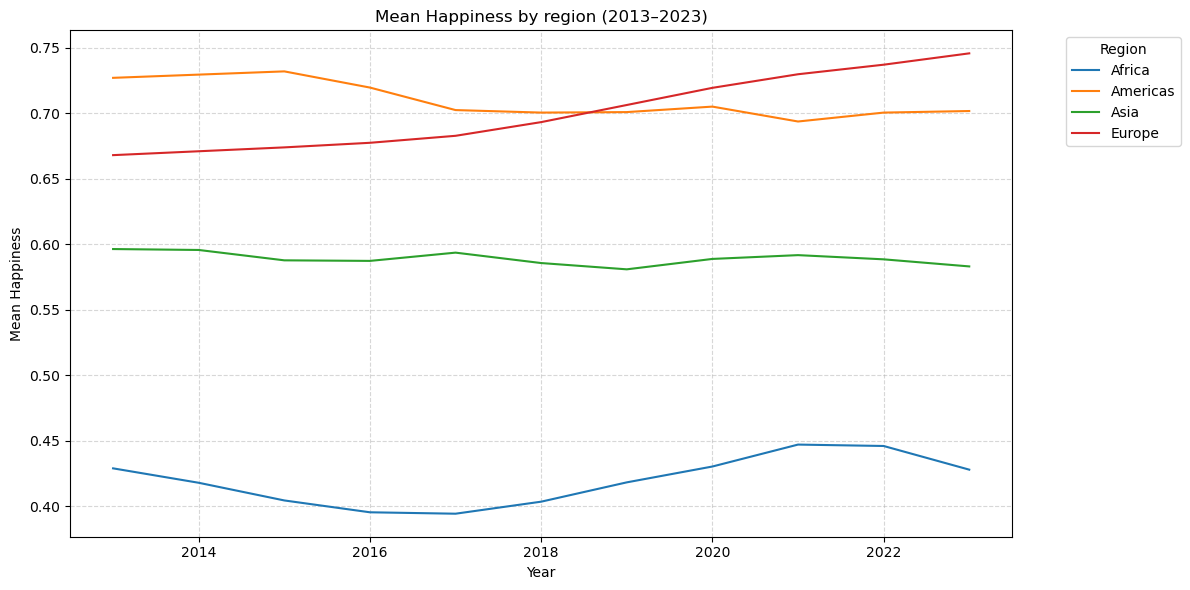

Saved: Happiness_mean.png


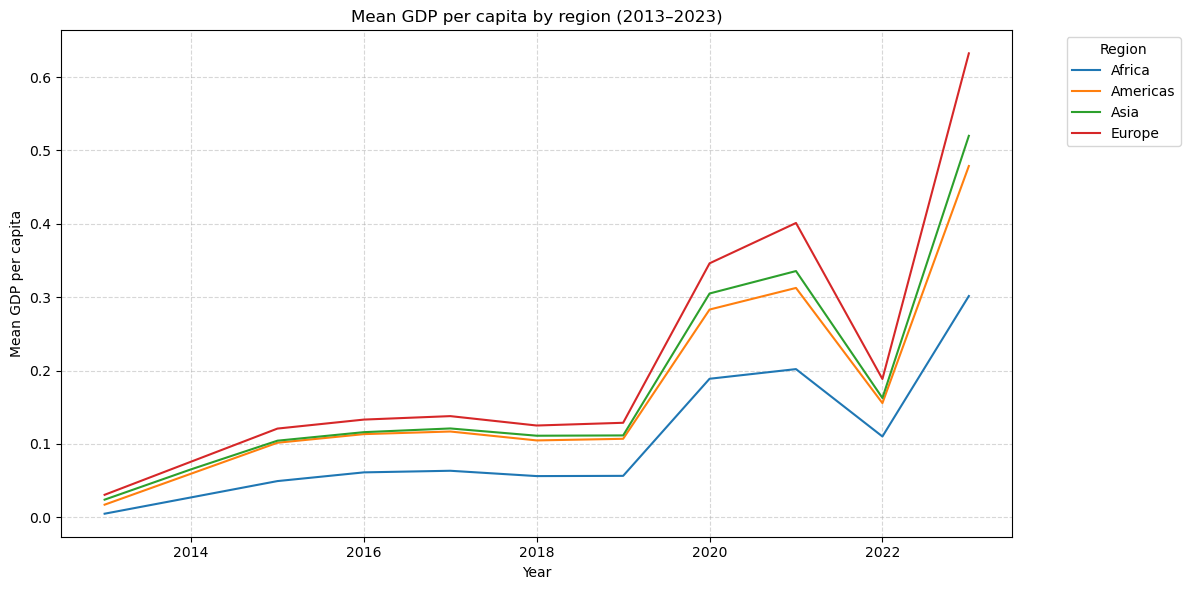

Saved: GDP_per_capita_mean.png


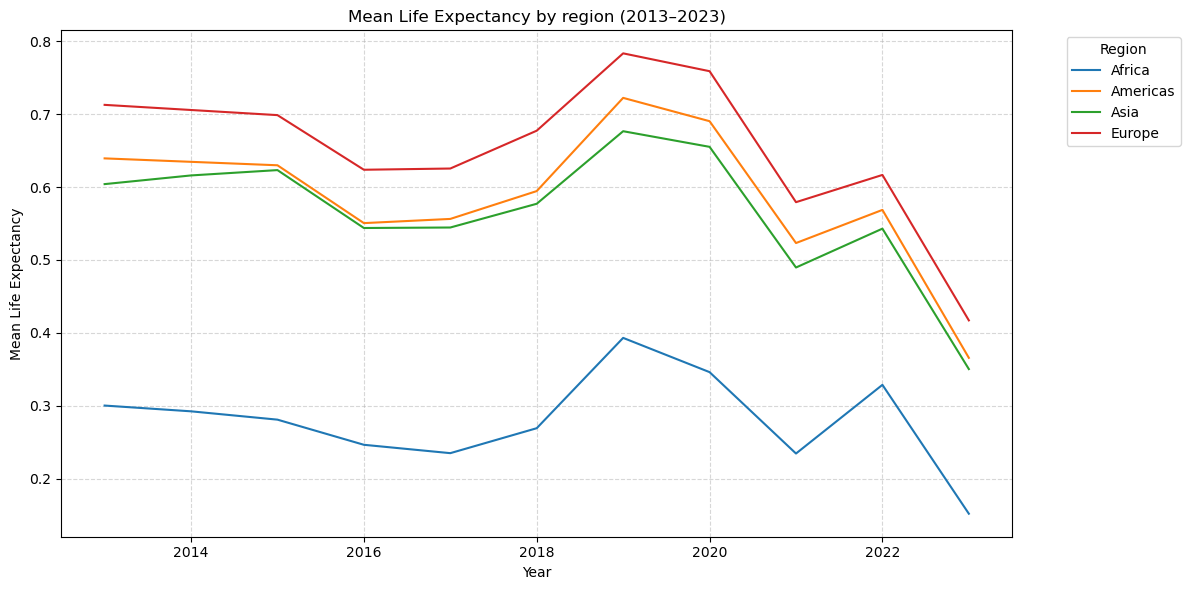

Saved: Life_Expectancy_mean.png


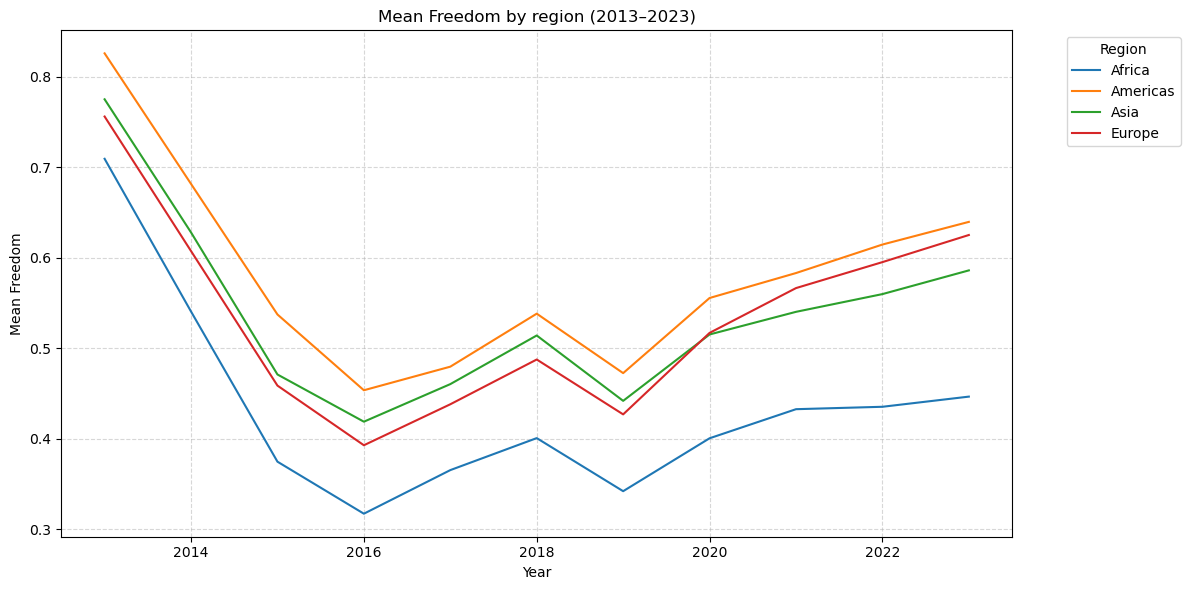

Saved: Freedom_mean.png


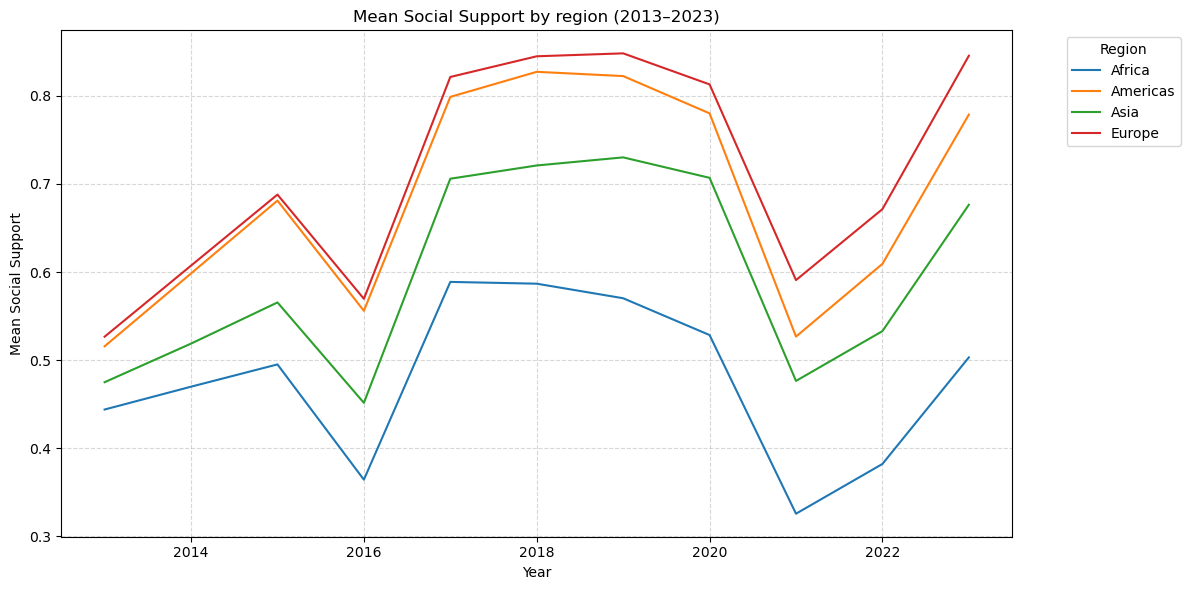

Saved: Social_Support_mean.png


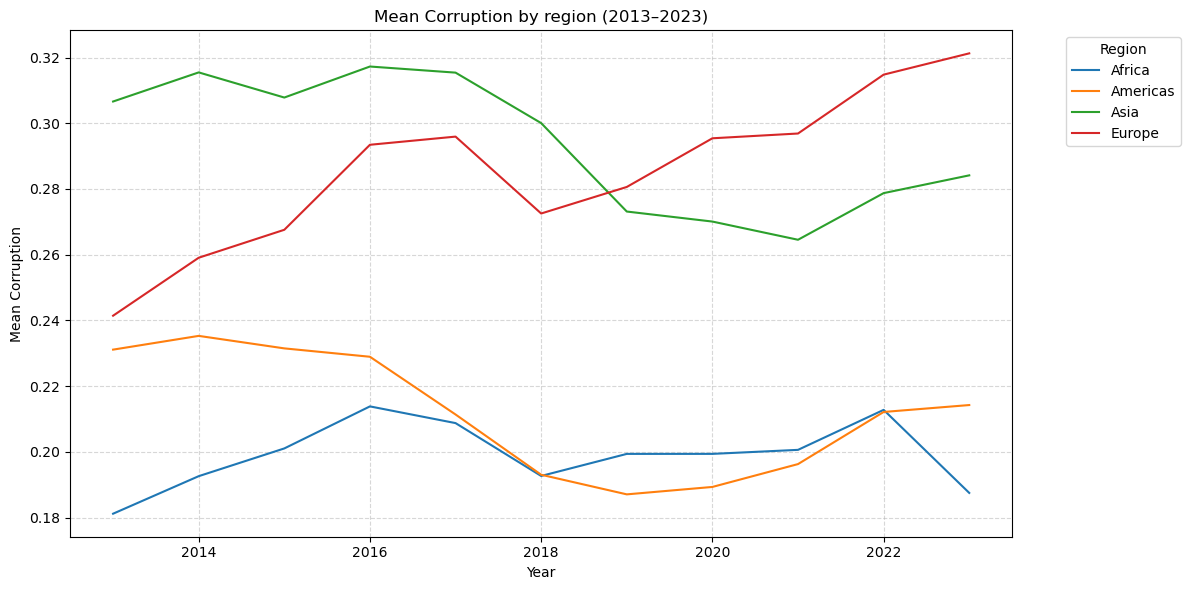

Saved: Corruption_mean.png
Aggregates per region (MinMax-scaled indicators):
         Happiness                                 GDP per capita                                 Life Expectancy                                 Freedom                                 Social Support                                 Corruption                                
              mean  median     std     min     max           mean  median     std     min     max            mean  median     std     min     max    mean  median     std     min     max           mean  median     std     min     max       mean  median     std     min     max
Region                                                                                                                                                                                                                                                                             
Africa      0.4192  0.4225  0.1088  0.1394  0.7515         0.0995  0.0702  0.0960  0.0000  0.54

In [25]:
# ---------------------------------------------------------------
# Cell 21 - Regional trends
#
# One line per region per indicator, showing the mean across
# countries for each year. Each figure is closed after saving to
# avoid leaking memory in long notebook sessions.
# Also, the SAME information as a table: mean, median, std, min, max per
# region per indicator. Export to LaTeX for the report.
#
# Also prints the region ranking by MEAN Happiness (pooled over
# years), which is the single most useful summary for the report.
# ---------------------------------------------------------------

for var in SCALE_COLS:
    data = df_minmax.groupby(["Region", "Year"])[var].mean().reset_index()

    fig, ax = plt.subplots(figsize=(12, 6))
    sns.lineplot(data=data, x="Year", y=var, hue="Region", ax=ax)
    ax.set_title(f"Mean {var} by region (2013–2023)")
    ax.set_xlabel("Year")
    ax.set_ylabel(f"Mean {var}")
    ax.legend(title="Region", bbox_to_anchor=(1.05, 1), loc="upper left")
    ax.grid(True, linestyle="--", alpha=0.5)
    fig.tight_layout()

    fname = f"{var.replace(' ', '_')}_mean.png"
    fig.savefig(FIGURES_DIR / fname, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {fname}")

agg_by_region = (
    df_minmax
    .groupby("Region")[SCALE_COLS]
    .agg(["mean", "median", "std", "min", "max"])
    .round(4)
)

print("Aggregates per region (MinMax-scaled indicators):")
print(agg_by_region.to_string())

# Export to LaTeX
agg_by_region.to_latex(
    DOCS_DIR / "region_aggregates.tex",
    caption=(
        "Mean, median, standard deviation, min and max of the six "
        "core indicators per region (MinMax-scaled)."
    ),
    label="tab:region-agg",
    float_format="%.4f",
)
print(f"\nExported: ./docs/tables/region_aggregates.tex")

# Compact ranking by mean Happiness (useful for the report)
happiness_ranking = (
    df_minmax
    .groupby("Region")["Happiness"]
    .mean()
    .sort_values(ascending=False)
    .round(4)
    .to_frame("mean_Happiness")
    .assign(rank=lambda d: range(1, len(d) + 1))
)

print("\nRegions ranked by mean Happiness (pooled over 2013-2023):")
print(happiness_ranking.to_string())

happiness_ranking.reset_index().to_latex(
    DOCS_DIR / "region_happiness_ranking.tex",
    index=False,
    caption="Regions ranked by mean Happiness (MinMax-scaled, pooled over years).",
    label="tab:region-rank",
    float_format="%.4f",
)

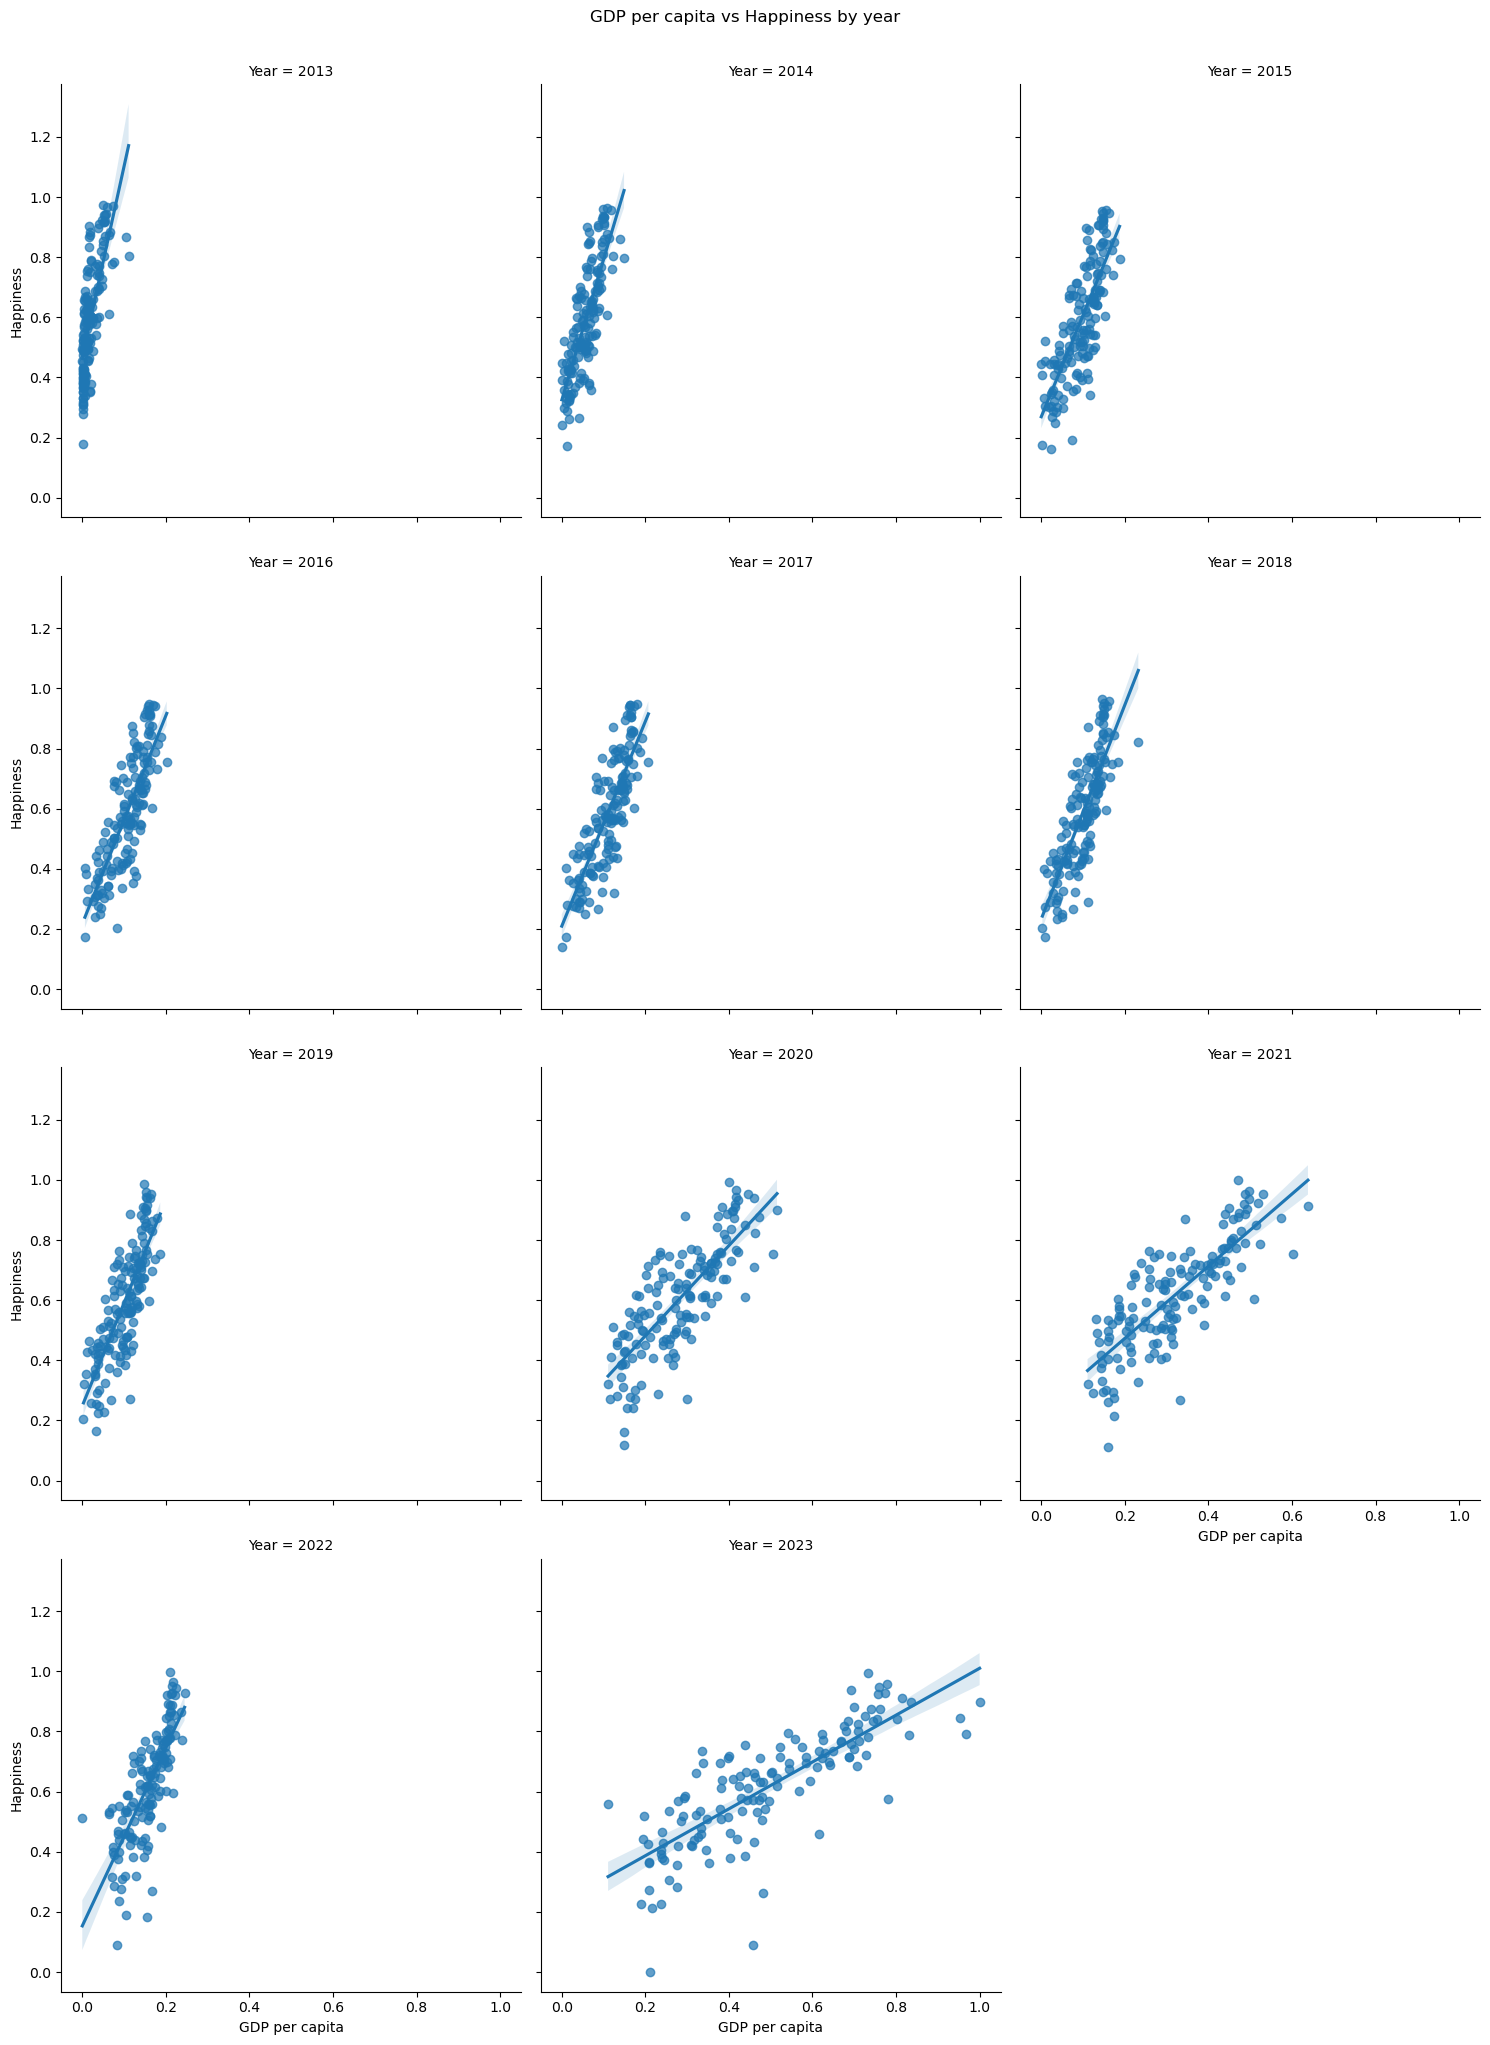

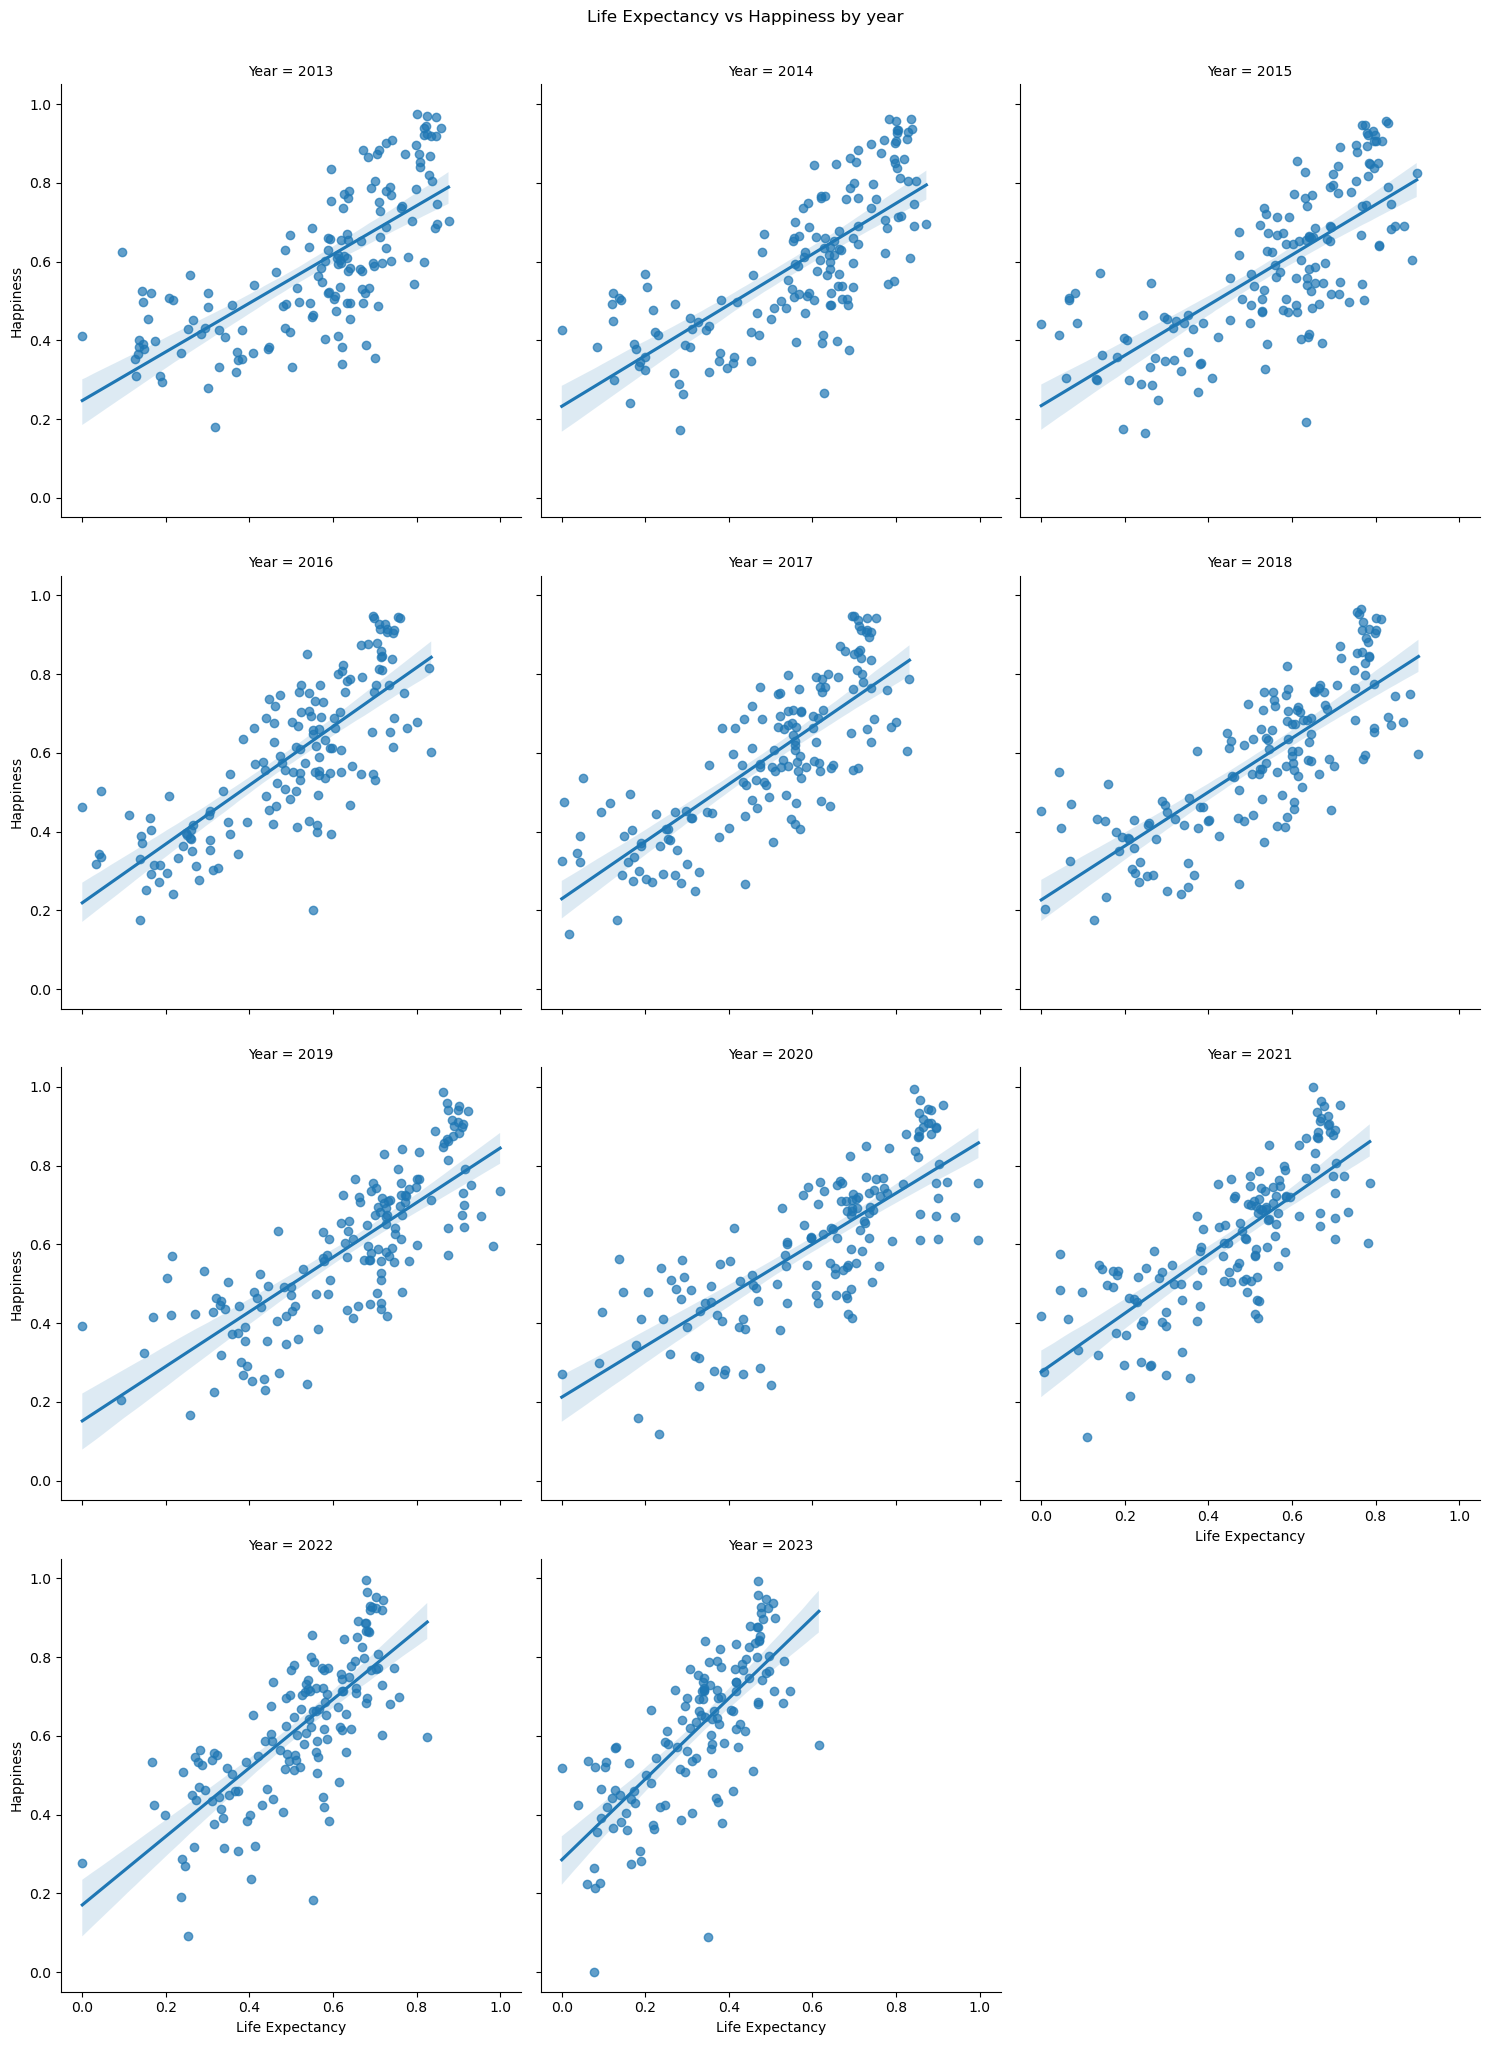

Saved: Life_Expectancy_vs_Happiness.png


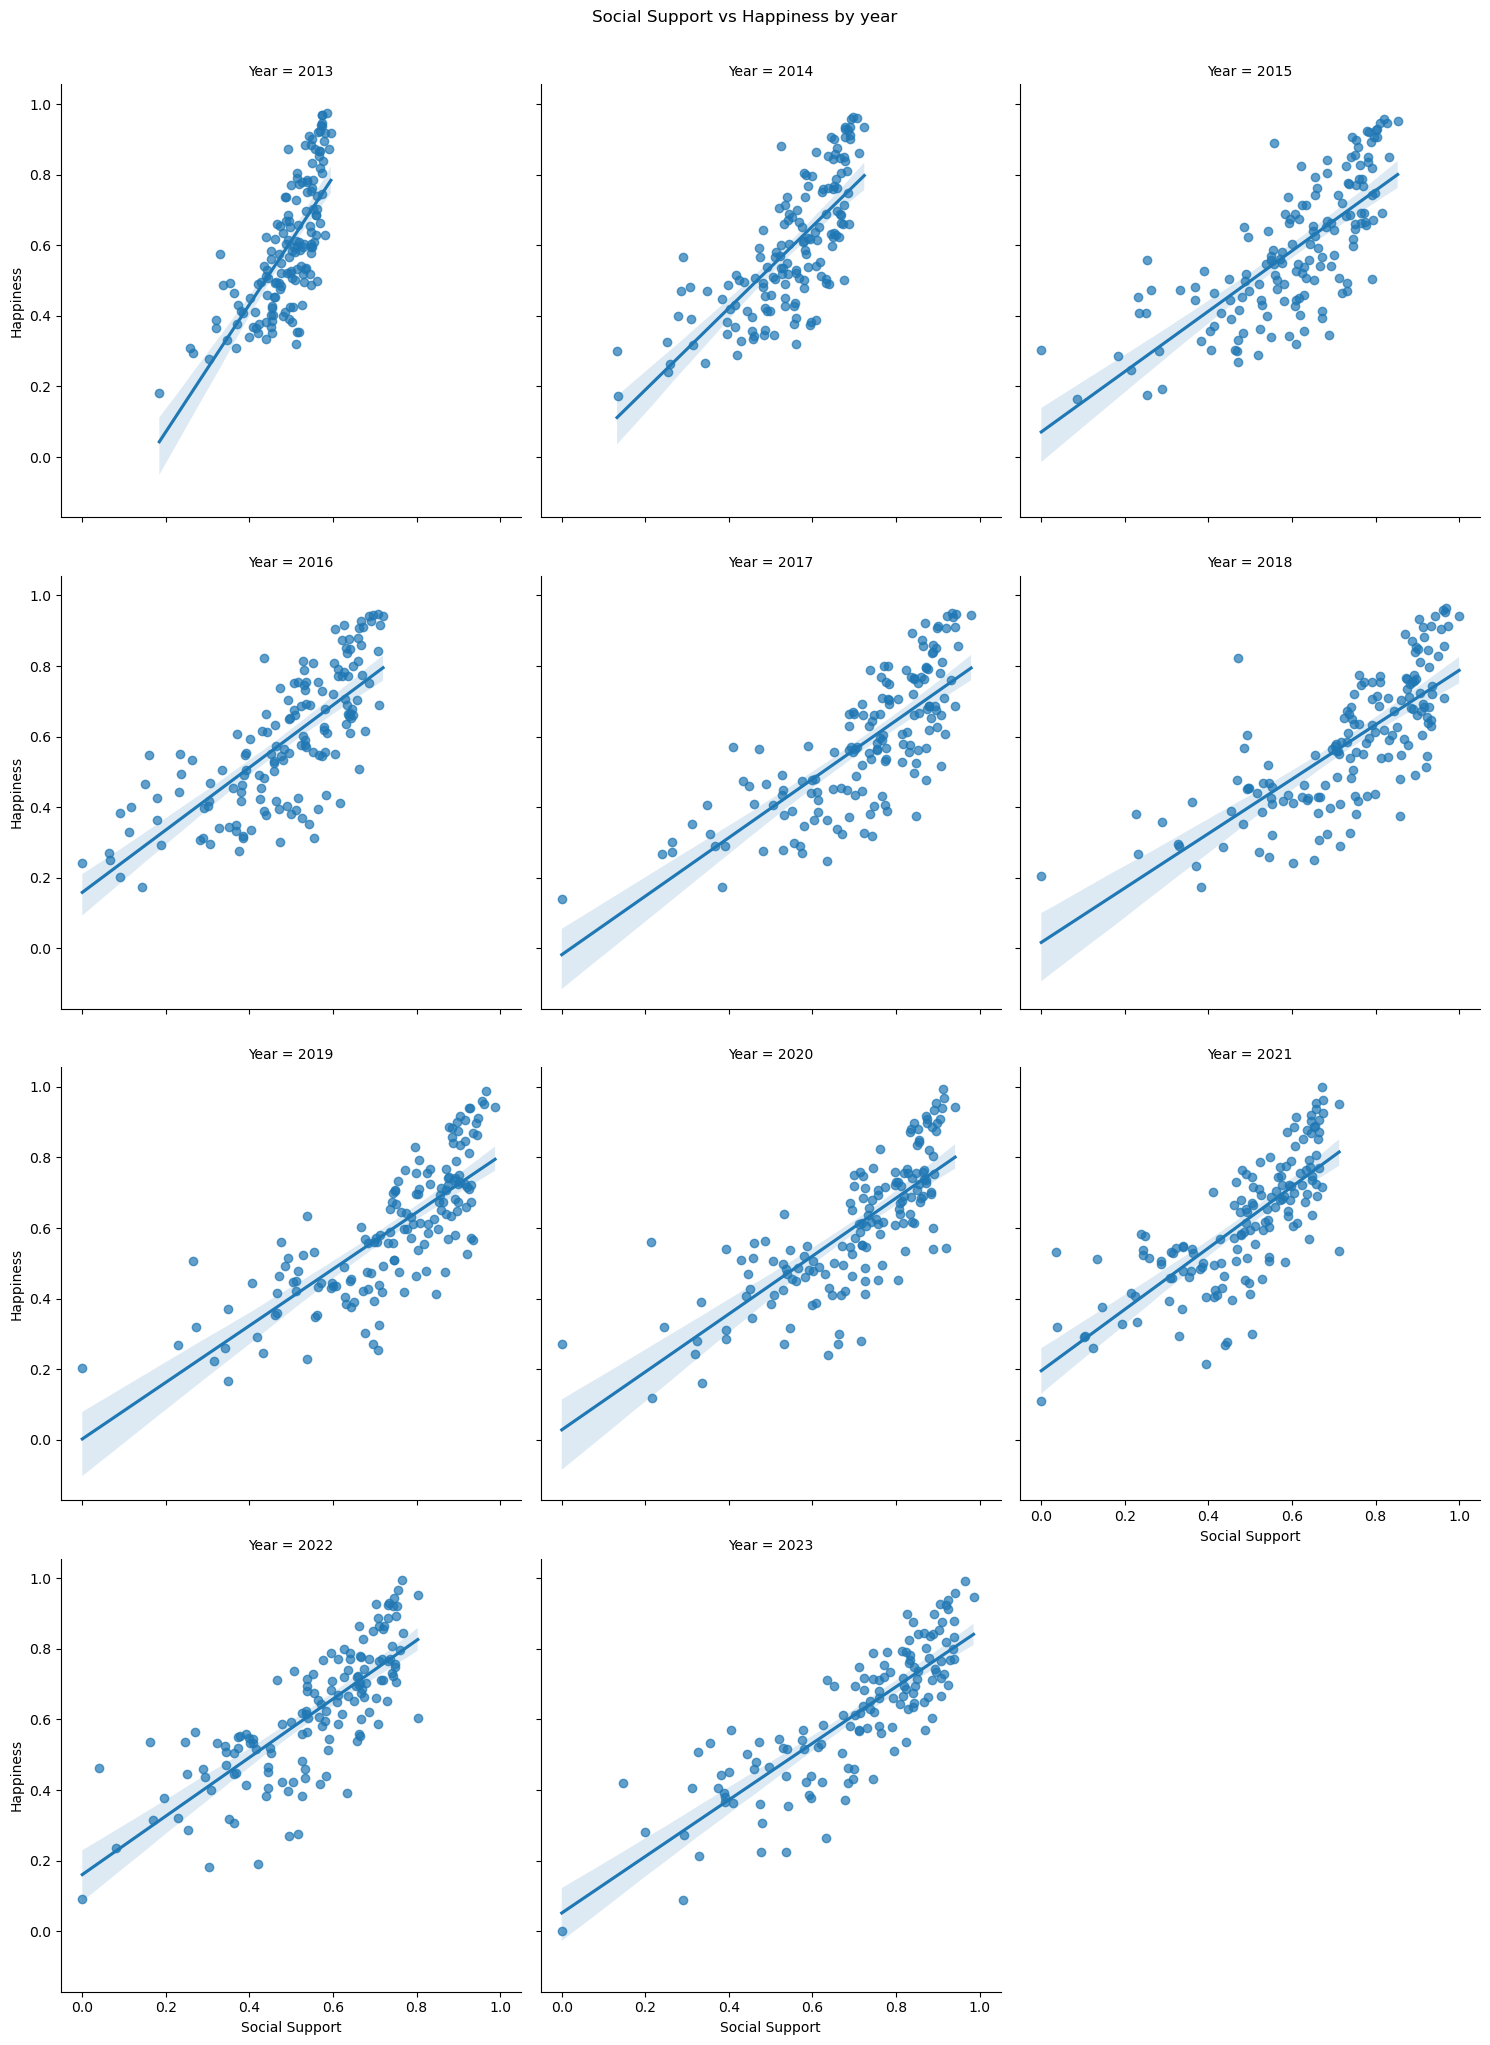

Saved: Social_Support_vs_Happiness.png


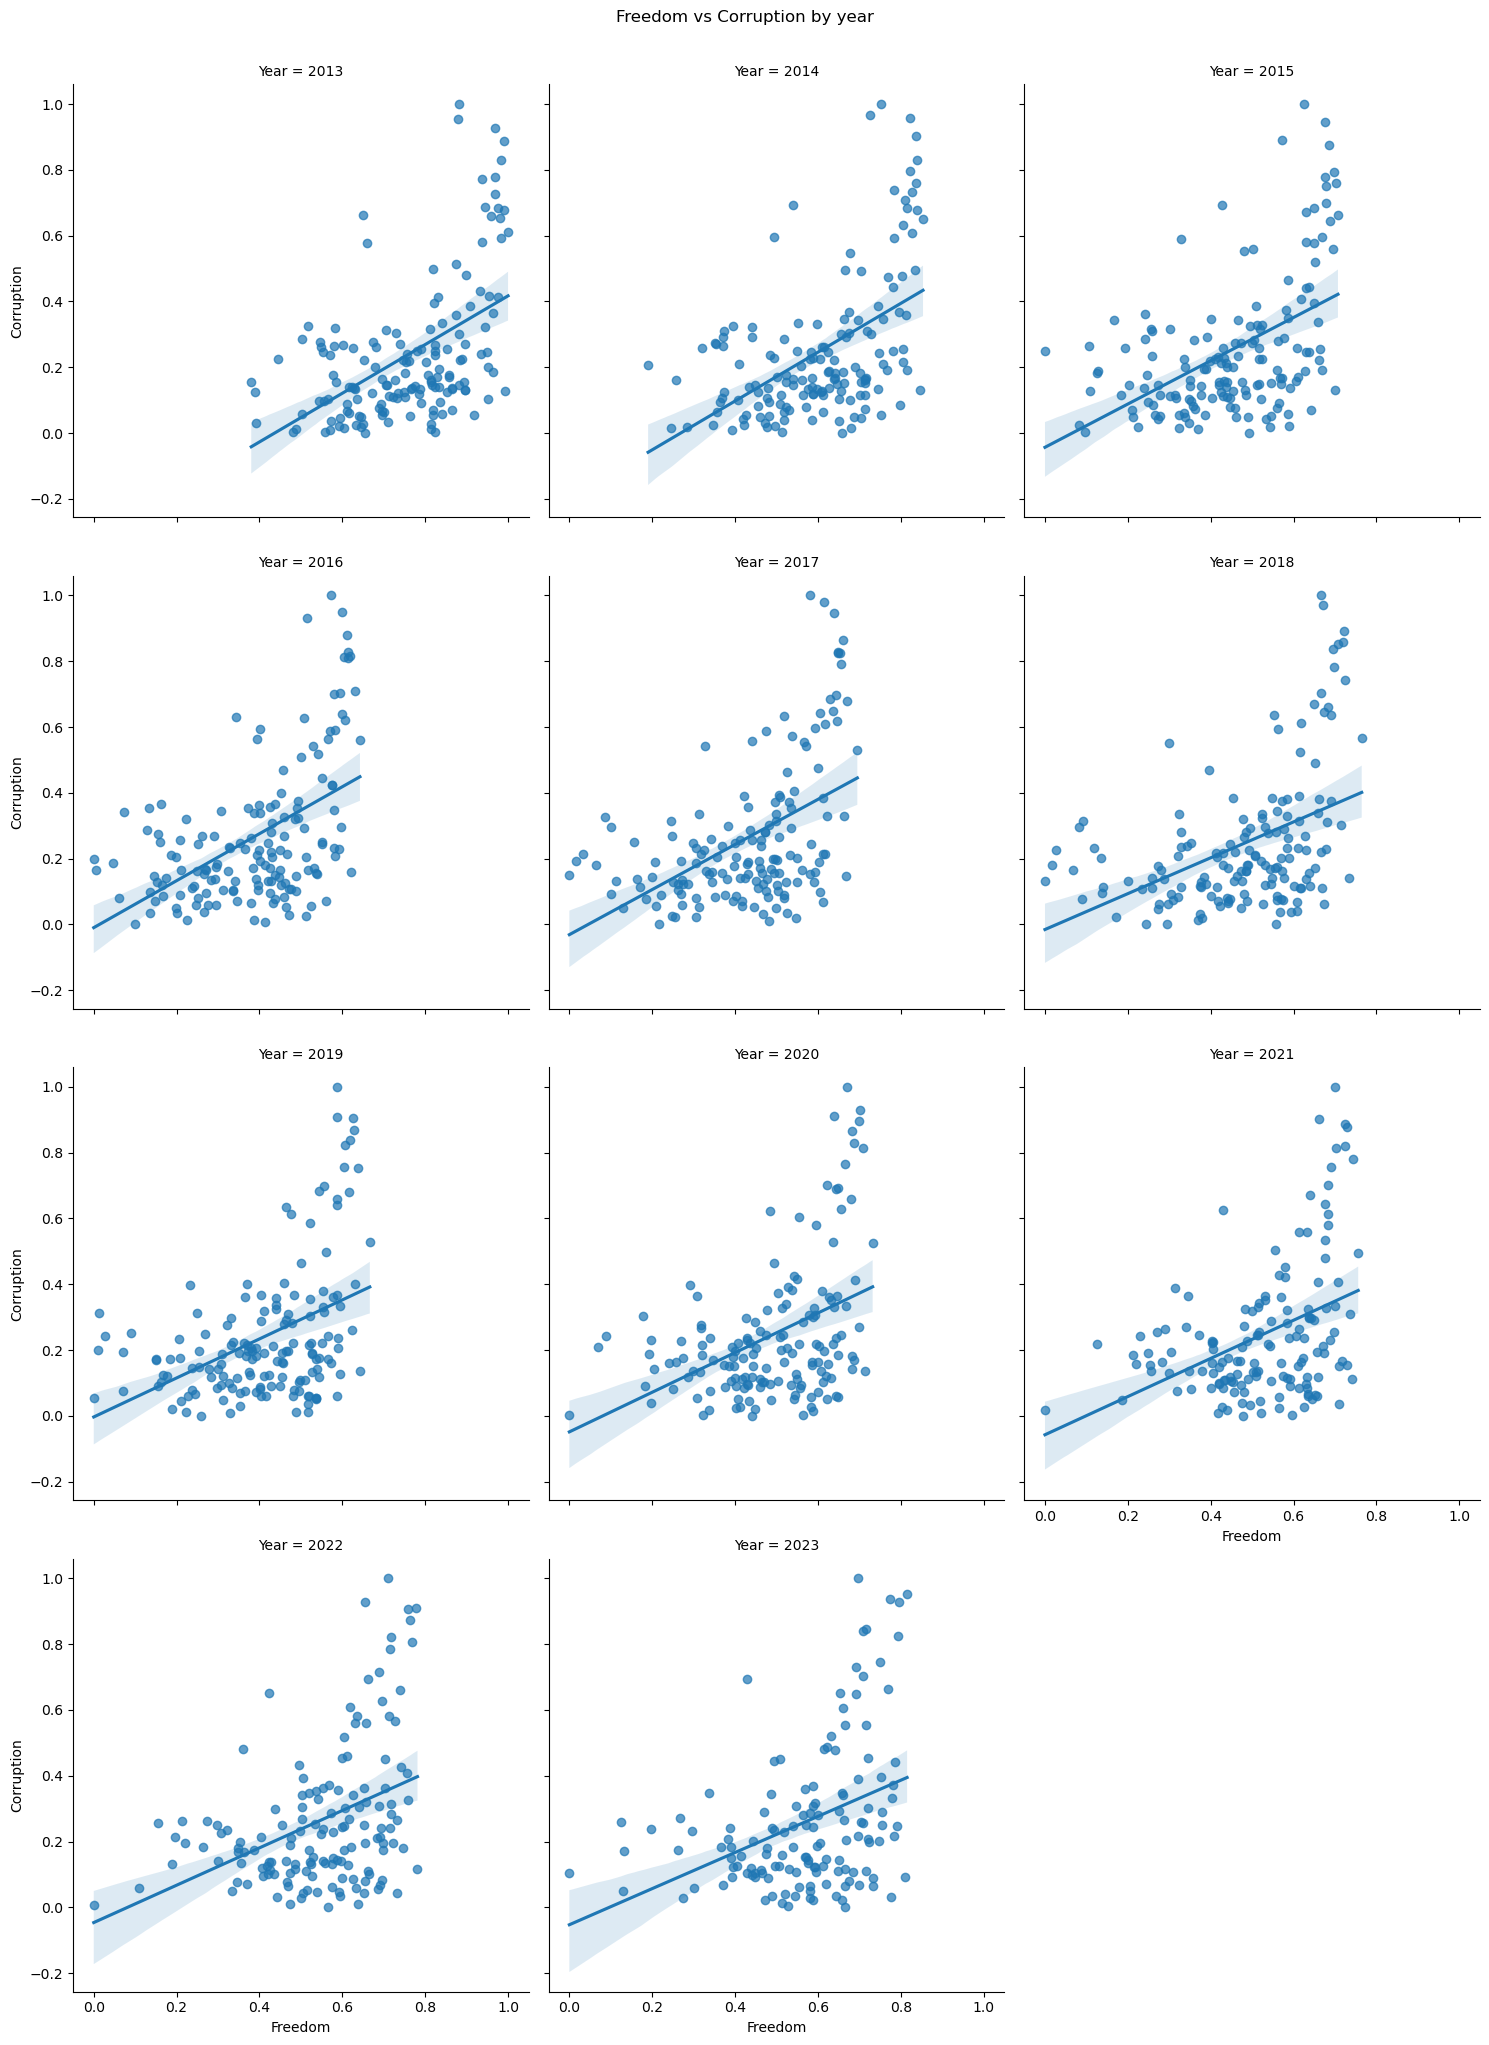

Saved: Freedom_vs_Corruption.png


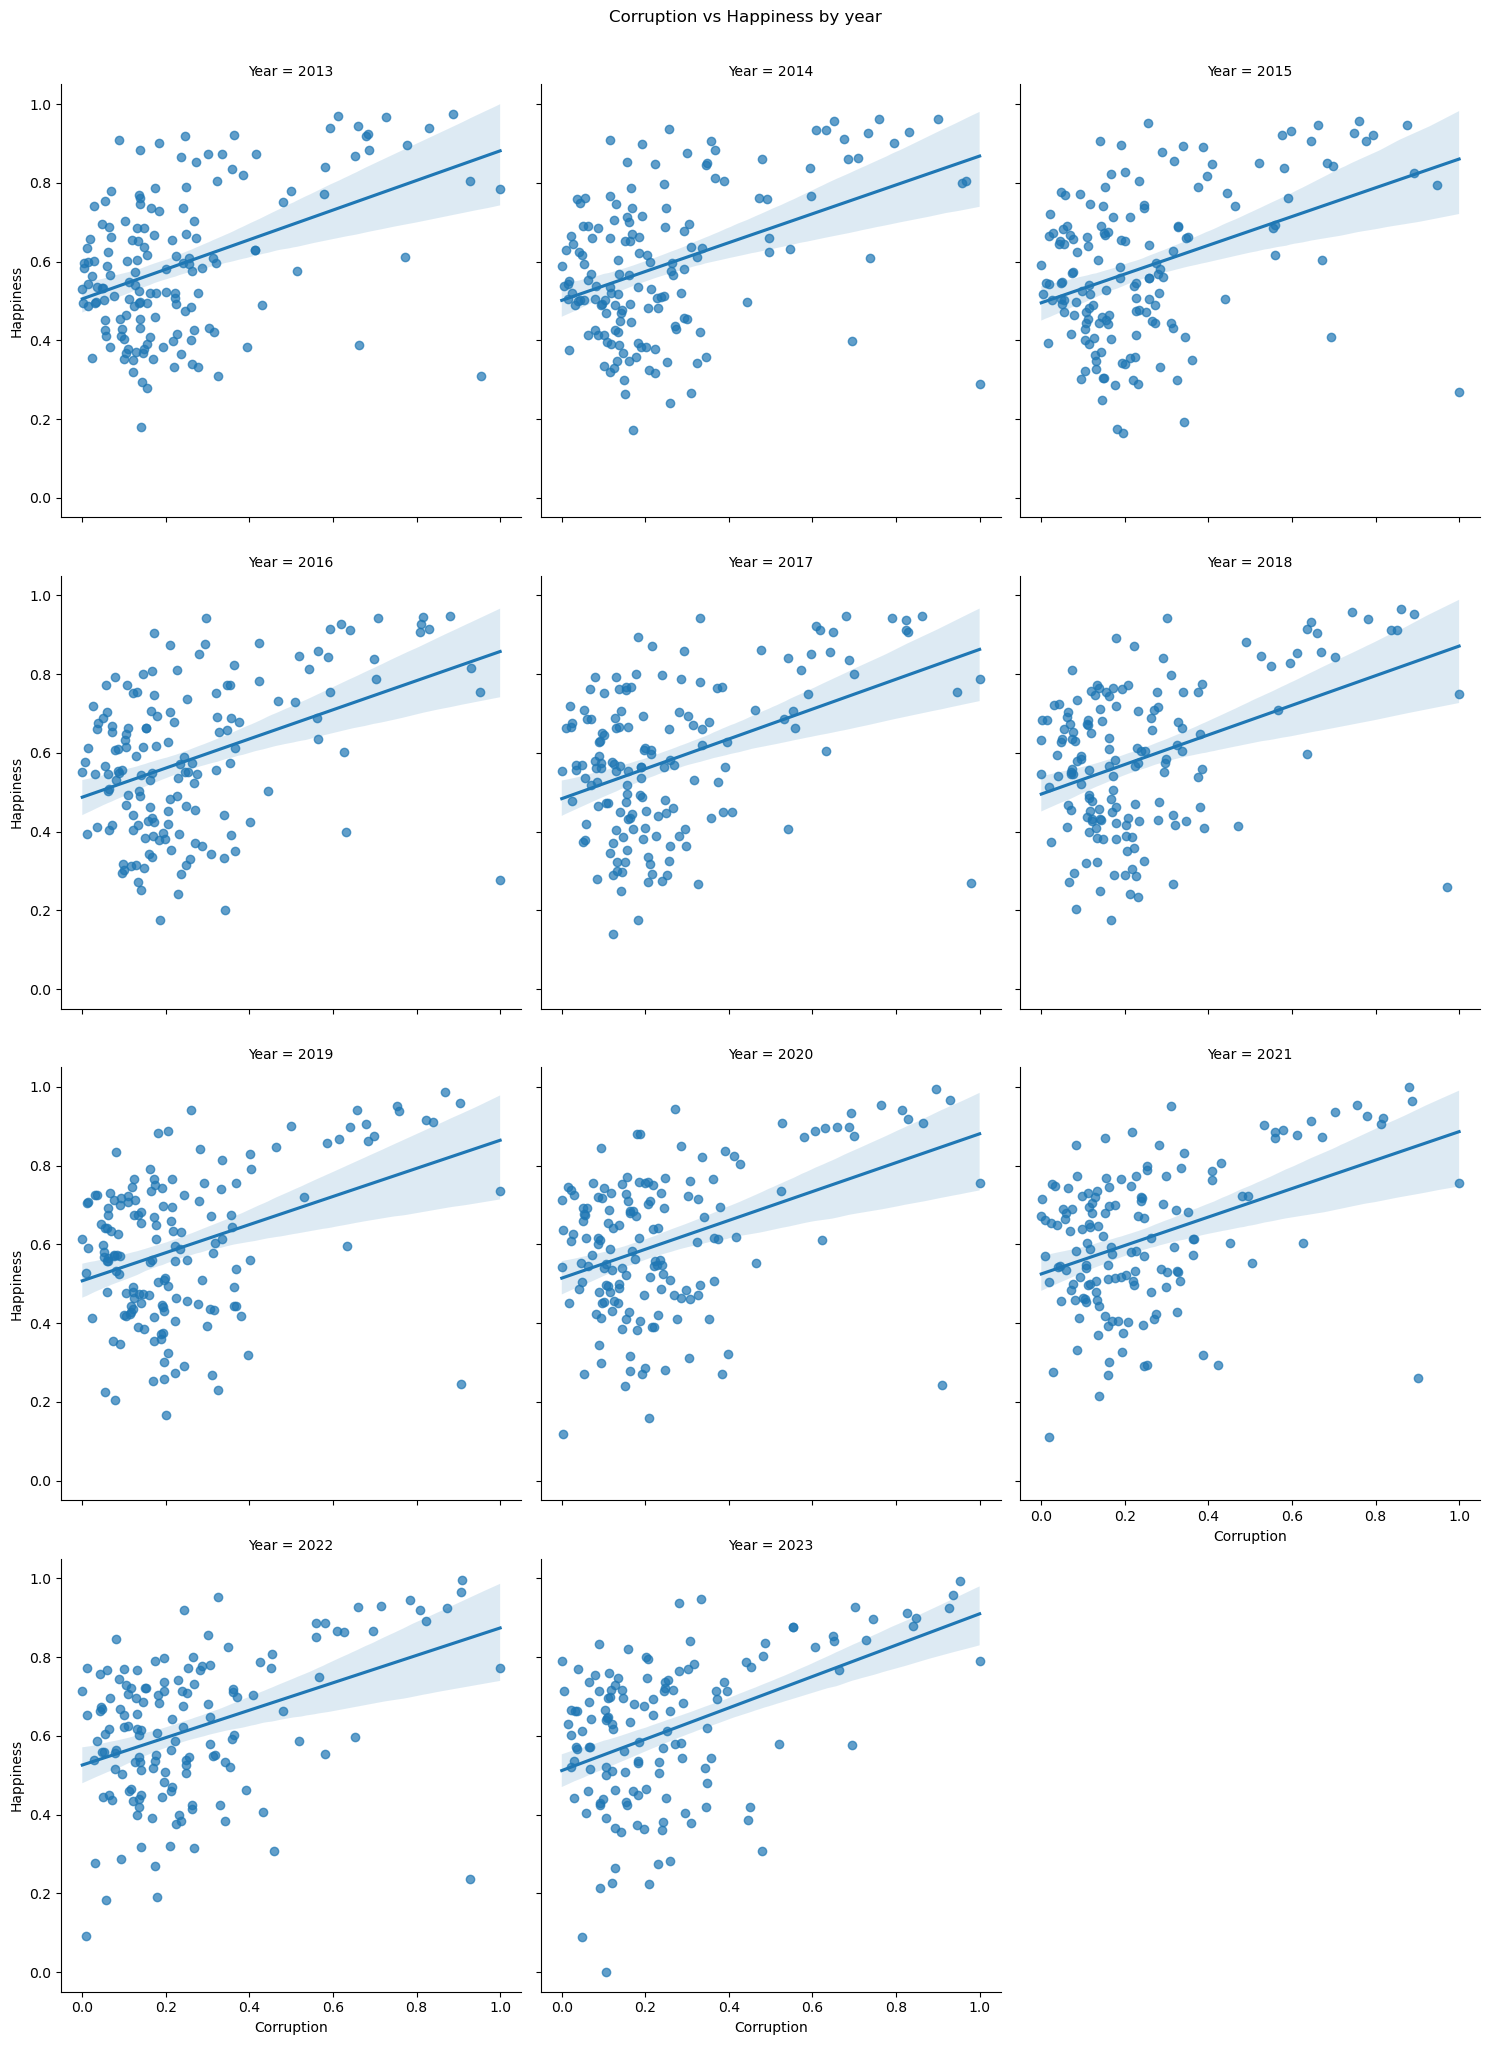

Saved: Corruption_vs_Happiness.png


In [26]:
# ---------------------------------------------------------------
# Cell 22 -  Bivariate relationships
#
# lmplot returns a FacetGrid; we save through g.fig.savefig to make
# sure the whole facet grid ends up in the file (bug #19).
# ---------------------------------------------------------------

# GDP per capita vs Happiness, faceted by year.
g = sns.lmplot(
    data=df_minmax, x="GDP per capita", y="Happiness",
    col="Year", col_wrap=3, scatter_kws={"alpha": 0.7},
)
g.fig.suptitle("GDP per capita vs Happiness by year", y=1.02)
g.fig.savefig(FIGURES_DIR / "GDP_vs_Happiness_by_year.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(g.fig)

# Other interesting pairs.
SCATTER_PAIRS = [
    ("Life Expectancy", "Happiness"),
    ("Social Support", "Happiness"),
    ("Freedom", "Corruption"),
    ("Corruption", "Happiness"),
]

for var1, var2 in SCATTER_PAIRS:
    g = sns.lmplot(
        data=df_minmax, x=var1, y=var2,
        col="Year", col_wrap=3, scatter_kws={"alpha": 0.7},
    )
    g.fig.suptitle(f"{var1} vs {var2} by year", y=1.02)
    fname = f"{var1.replace(' ', '_')}_vs_{var2.replace(' ', '_')}.png"
    g.fig.savefig(FIGURES_DIR / fname, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(g.fig)
    print(f"Saved: {fname}")

In [27]:
# ---------------------------------------------------------------
# Cell 23 - Spearman robustness check
#
# GDP per capita is right-skewed (log-normal). Pearson may
# underestimate its relationship with Happiness. Spearman is a
# rank correlation, robust to skew, and complements Pearson.
# ---------------------------------------------------------------

spearman = df_minmax[SCALE_COLS].corr(method="spearman")
print("Spearman rank correlations:")
print(spearman.round(3).to_string())

Spearman rank correlations:
                 Happiness  GDP per capita  Life Expectancy  Freedom  Social Support  Corruption
Happiness            1.000           0.448            0.699    0.490           0.615       0.304
GDP per capita       0.448           1.000            0.208    0.080           0.418       0.132
Life Expectancy      0.699           0.208            1.000    0.279           0.489       0.181
Freedom              0.490           0.080            0.279    1.000           0.188       0.322
Social Support       0.615           0.418            0.489    0.188           1.000       0.106
Corruption           0.304           0.132            0.181    0.322           0.106       1.000


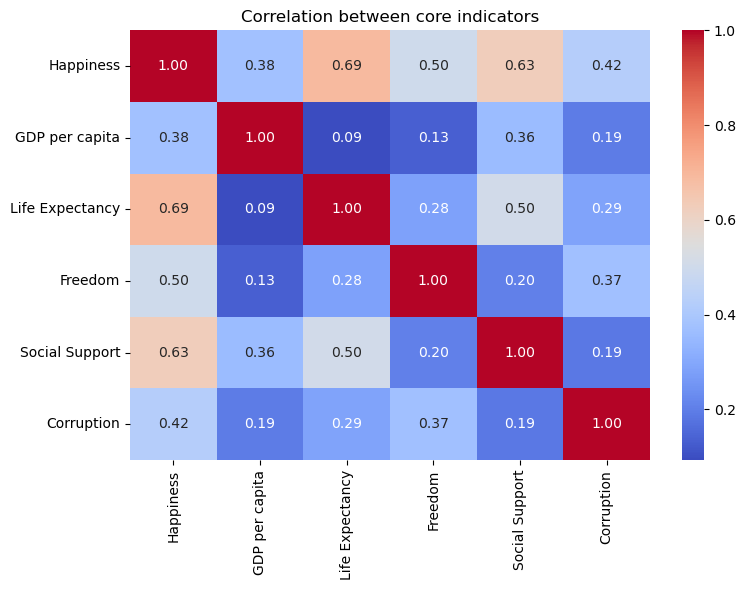

Exported: ./docs/tables/correlation.tex


In [28]:
# ---------------------------------------------------------------
# Cell 24 - Correlation matrix
# ---------------------------------------------------------------

corr = df_minmax[SCALE_COLS].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=ax)
ax.set_title("Correlation between core indicators")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

corr.round(3).rename_axis("Indicator").reset_index().to_latex(
    DOCS_DIR / "correlation.tex",
    index=False,
    caption="Pearson correlation between the six core indicators (MinMax-scaled).",
    label="tab:correlation",
    float_format="%.3f",
)
print("Exported: ./docs/tables/correlation.tex")

In [29]:
# ---------------------------------------------------------------
# Cell 23 - Top / Bottom by subregion and continent
#
# Two presentation levels:
#   1. Subregions with n >= MIN_COUNTRIES_SUBREGION (7):
#      table with top 4 + bottom 4 countries + LaTeX export.
#   2. Subregions with n < 8: prose paragraph listing every country
#      in descending Happiness order (no top/bottom split, since
#      the whole subregion fits in one sentence).
#   3. Continents: top 20 + bottom 20 (Americas uses 13+13 because
#      it only has 26 countries; exact coverage without overlap).
#
# Ranks are computed per subregion and per continent, not globally.
# Global top 20 / bottom 20 is exported separately by Cell 23b.
# ---------------------------------------------------------------

country_mean = (
    df_minmax
    .groupby(["Region", "Subregion", "Country"])["Happiness"]
    .mean()
    .reset_index()
)

n_by_subregion = country_mean.groupby("Subregion")["Country"].nunique()
table_sub = sorted(n_by_subregion[n_by_subregion >= MIN_COUNTRIES_SUBREGION].index)
prose_sub = sorted(n_by_subregion[n_by_subregion < MIN_COUNTRIES_SUBREGION].index)

# ---- Subregion level: tables (n >= 8) ----
print("=" * 70)
print(f"SUBSREGIONS WITH n >= {MIN_COUNTRIES_SUBREGION}: top {TOP_N_SUBREGION} + bottom {BOTTOM_N_SUBREGION}")
print("=" * 70)

pieces = []
for subregion in table_sub:
    sub = (
        country_mean[country_mean["Subregion"] == subregion]
        .sort_values("Happiness", ascending=False)
        .reset_index(drop=True)
    )
    sub["Subregion rank"] = range(1, len(sub) + 1)
    top = sub.head(TOP_N_SUBREGION).assign(Tier="Top")
    bottom = sub.tail(BOTTOM_N_SUBREGION).assign(Tier="Bottom")
    pieces.append(pd.concat([top, bottom]))

top_bottom_sub = (
    pd.concat(pieces)
    [["Subregion", "Tier", "Subregion rank", "Country", "Happiness"]]
    .round({"Happiness": 4})
    .reset_index(drop=True)
)

print(top_bottom_sub.to_string(index=False))

top_bottom_sub.to_latex(
    DOCS_DIR / "top_bottom_by_subregion.tex",
    index=False,
    caption=(
        f"Top {TOP_N_SUBREGION} and bottom {BOTTOM_N_SUBREGION} countries per "
        f"subregion, ranked by mean Happiness across 2013-2023 "
        f"(MinMax-scaled). Only subregions with $\\geq {MIN_COUNTRIES_SUBREGION}$ "
        f"countries are included."
    ),
    label="tab:top-bottom-sub",
    float_format="%.4f",
)
print(f"\nExported: ./docs/tables/top_bottom_by_subregion.tex")

# ---- Subregion level: prose (n < 8) ----
print("\n" + "=" * 70)
print(f"SUBSREGIONS WITH n < {MIN_COUNTRIES_SUBREGION}: prose listing")
print("=" * 70)

for subregion in prose_sub:
    sub = (
        country_mean[country_mean["Subregion"] == subregion]
        .sort_values("Happiness", ascending=False)
        .reset_index(drop=True)
    )
    items = "; ".join(
        f"{row['Country']} ({row['Happiness']:.3f})"
        for _, row in sub.iterrows()
    )
    print(f"\n{subregion} (n={len(sub)}):")
    print(f"  {items}")

# ---- Continent level ----
print("\n" + "=" * 70)
print("CONTINENT LEVEL: top + bottom per continent")
print("=" * 70)

cont_pieces = []
for continent in sorted(country_mean["Region"].unique()):
    sub = (
        country_mean[country_mean["Region"] == continent]
        .sort_values("Happiness", ascending=False)
        .reset_index(drop=True)
    )
    sub["Region rank"] = range(1, len(sub) + 1)
    n = len(sub)

    if continent == "Americas":
        top_n, bottom_n = TOP_N_AMERICAS, BOTTOM_N_AMERICAS
    else:
        top_n, bottom_n = TOP_N_CONTINENT, BOTTOM_N_CONTINENT

    # Safety guard: avoid overlap if the continent is small
    top_n = min(top_n, n // 2)
    bottom_n = min(bottom_n, n - top_n)

    top = sub.head(top_n).assign(Tier="Top")
    bottom = sub.tail(bottom_n).assign(Tier="Bottom")
    cont_df = pd.concat([top, bottom])
    cont_pieces.append(cont_df)

    print(f"\n{continent} (n={n}): top {top_n} + bottom {bottom_n}")
    print(cont_df[["Tier", "Region rank", "Country", "Happiness"]].round(4).to_string(index=False))

top_bottom_cont = (
    pd.concat(cont_pieces)
    [["Region", "Tier", "Region rank", "Country", "Happiness"]]
    .round({"Happiness": 4})
    .reset_index(drop=True)
)

top_bottom_cont.to_latex(
    DOCS_DIR / "top_bottom_by_continent.tex",
    index=False,
    caption=(
        f"Top {TOP_N_CONTINENT} and bottom {BOTTOM_N_CONTINENT} countries per "
        f"continent, ranked by mean Happiness across 2013-2023. The Americas "
        f"is reported with top {TOP_N_AMERICAS} + bottom {BOTTOM_N_AMERICAS} "
        f"because it has only 26 countries."
    ),
    label="tab:top-bottom-cont",
    float_format="%.4f",
)
print("\nExported: ./docs/tables/top_bottom_by_continent.tex")

# ---- Global Top 20 / Bottom 20 (across all countries) ----
print("\n" + "=" * 70)
print("GLOBAL: top 20 + bottom 20 by country")
print("=" * 70)

N_GLOBAL = 20

global_sorted = country_mean.sort_values("Happiness", ascending=False).reset_index(drop=True)
global_sorted["Global rank"] = range(1, len(global_sorted) + 1)

top_global = global_sorted.head(N_GLOBAL).assign(Tier="Top")
bottom_global = global_sorted.tail(N_GLOBAL).assign(Tier="Bottom")

top_bottom_global = (
    pd.concat([top_global, bottom_global])
    [["Tier", "Global rank", "Country", "Region", "Subregion", "Happiness"]]
    .round({"Happiness": 4})
    .reset_index(drop=True)
)

print(top_bottom_global.to_string(index=False))

top_bottom_global.to_latex(
    DOCS_DIR / "top_bottom_global.tex",
    index=False,
    caption=(
        f"Global top {N_GLOBAL} and bottom {N_GLOBAL} countries by mean "
        "Happiness across 2013-2023 (MinMax-scaled). Global rank is "
        "out of all countries in the panel."
    ),
    label="tab:top-bottom-global",
    float_format="%.4f",
)
print(f"\nExported: ./docs/tables/top_bottom_global.tex")

SUBSREGIONS WITH n >= 7: top 4 + bottom 4
                  Subregion   Tier  Subregion rank                  Country  Happiness
 Central and Eastern Europe    Top               1           Czech Republic     0.8076
 Central and Eastern Europe    Top               2                 Slovakia     0.7220
 Central and Eastern Europe    Top               3                 Slovenia     0.7158
 Central and Eastern Europe    Top               4                Lithuania     0.6980
 Central and Eastern Europe Bottom              27                 Bulgaria     0.4851
 Central and Eastern Europe Bottom              28                  Armenia     0.4690
 Central and Eastern Europe Bottom              29                  Ukraine     0.4650
 Central and Eastern Europe Bottom              30                  Georgia     0.4455
Latin America and Caribbean    Top               1               Costa Rica     0.8670
Latin America and Caribbean    Top               2                   Mexico     0.7999
L

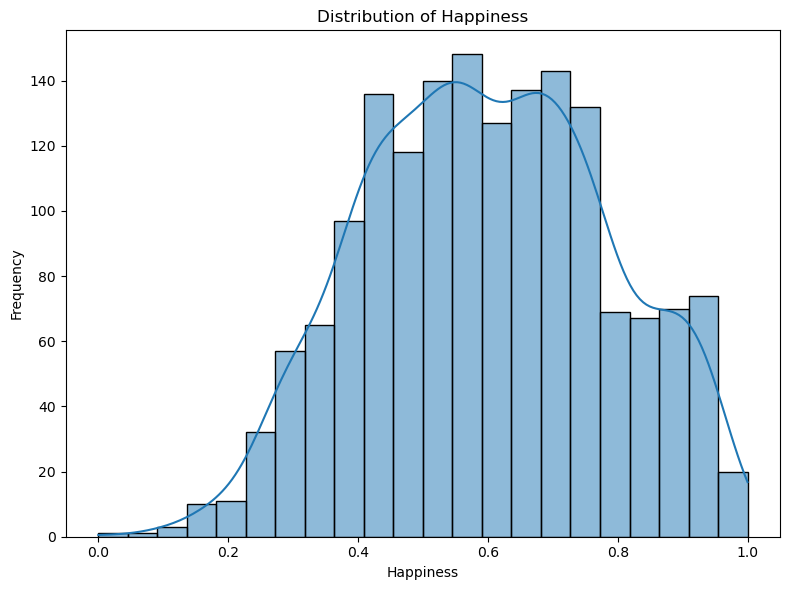

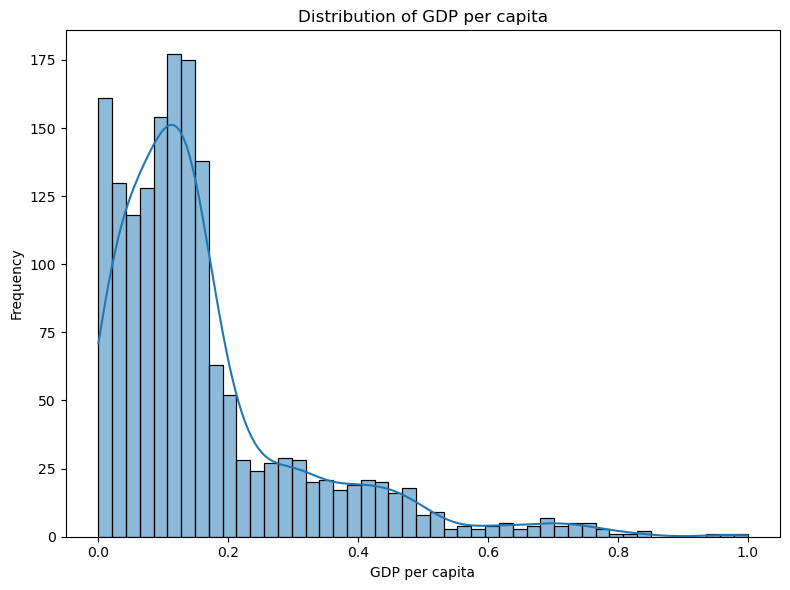

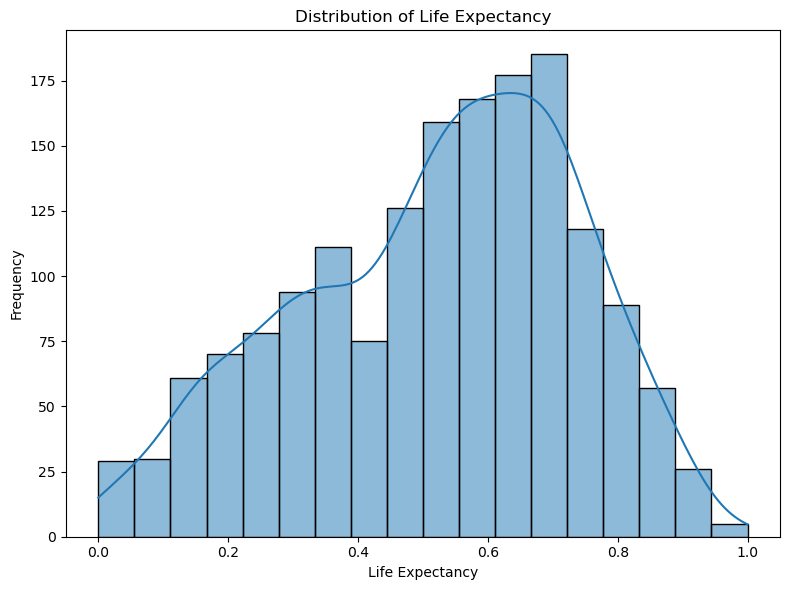

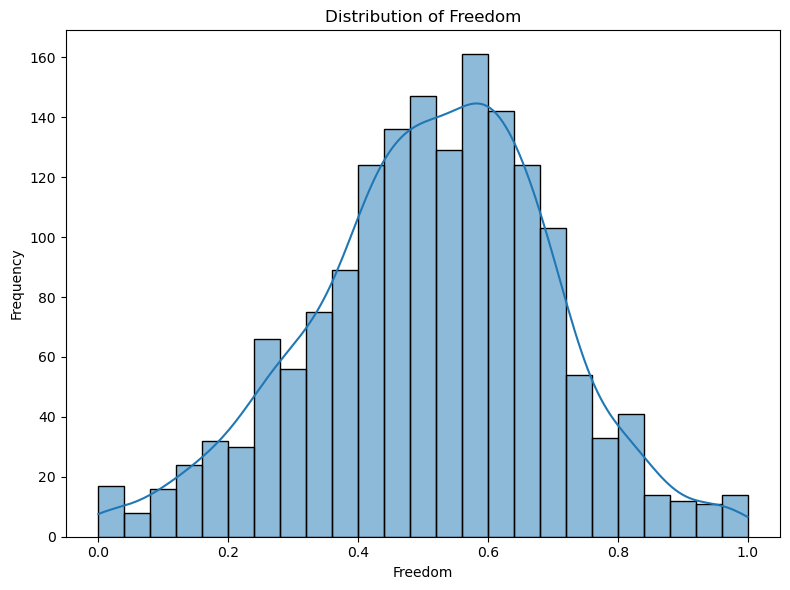

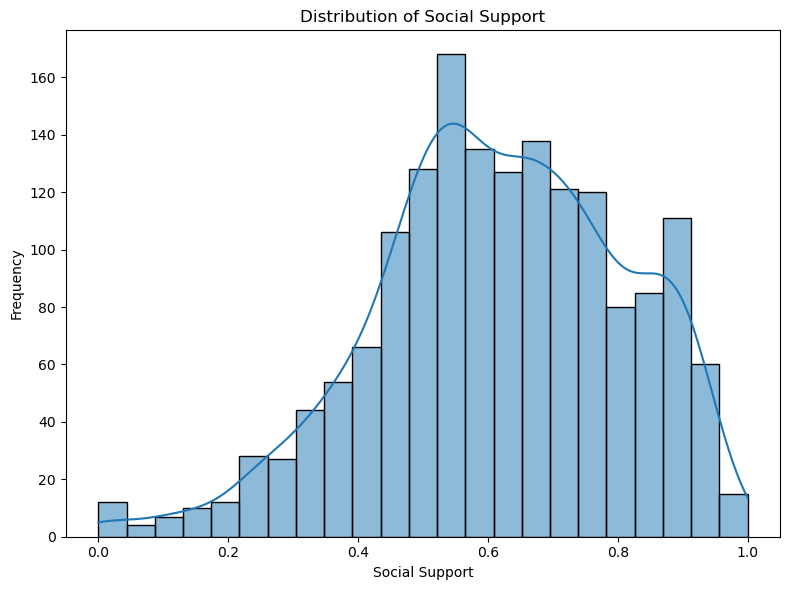

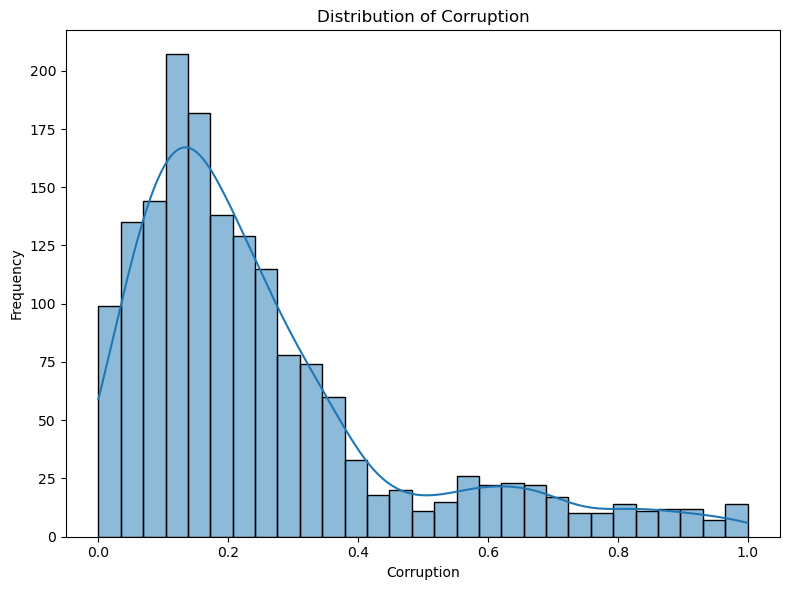

In [30]:
# ---------------------------------------------------------------
# Cell 26 - Univariate distributions
# ---------------------------------------------------------------

for var in SCALE_COLS:
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.histplot(df_minmax[var], kde=True, ax=ax)
    ax.set_title(f"Distribution of {var}")
    ax.set_xlabel(var)
    ax.set_ylabel("Frequency")
    fig.tight_layout()

    fname = f"{var.replace(' ', '_')}_hist.png"
    fig.savefig(FIGURES_DIR / fname, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [31]:
# Cell 27 - Correlation by region
regional_corr = (
    df_minmax.groupby("Region")
    .apply(lambda g: g[SCALE_COLS].corr().loc["Happiness"].drop("Happiness"),
    include_groups=False,
    )
    .round(3)
)
print("Correlation with Happiness, per region:")
print(regional_corr.to_string())

regional_corr.reset_index().to_latex(
    DOCS_DIR / "correlation_by_region.tex",
    index=False,
    caption=(
        "Correlation of each indicator with Happiness, computed WITHIN "
        "each region (Pearson, pooled over 2013-2023)."
    ),
    label="tab:corr-region",
    float_format="%.3f",
)
print("Exported: docs/tables/correlation_by_region.tex")

Correlation with Happiness, per region:
Happiness  GDP per capita  Life Expectancy  Freedom  Social Support  Corruption
Region                                                                         
Africa              0.274            0.322    0.144           0.341      -0.185
Americas            0.150            0.567    0.511           0.340       0.358
Asia                0.312            0.609    0.448           0.614       0.508
Europe              0.321            0.399    0.604           0.479       0.670
Exported: docs/tables/correlation_by_region.tex


In [32]:
# Cell 28 - Correlation with Happiness by year
corr_by_year = (
    df_minmax.groupby("Year")
    .apply(lambda g: g[SCALE_COLS].corr()["Happiness"].drop("Happiness"),
    include_groups=False,
    )
    .round(3)
)
print("Correlation with Happiness, per year:")
print(corr_by_year.T.to_string())

corr_by_year.T.to_latex(
    DOCS_DIR / "correlation_by_year.tex",
    caption=(
        "Correlation of each indicator with Happiness, per year "
        "(Pearson). Rows = indicators, columns = years."
    ),
    label="tab:corr-year",
    float_format="%.3f",
)
print("Exported: ./docs/tables/correlation_by_year.tex")

Correlation with Happiness, per year:
Year              2013   2014   2015   2016   2017   2018   2019   2020   2021   2022   2023
Happiness                                                                                   
GDP per capita   0.737  0.796  0.781  0.810  0.826  0.813  0.799  0.787  0.801  0.764  0.797
Life Expectancy  0.723  0.738  0.723  0.778  0.791  0.784  0.782  0.774  0.772  0.740  0.739
Freedom          0.556  0.572  0.567  0.568  0.574  0.550  0.575  0.592  0.610  0.625  0.663
Social Support   0.724  0.741  0.741  0.747  0.760  0.751  0.778  0.768  0.761  0.778  0.835
Corruption       0.442  0.432  0.407  0.420  0.436  0.422  0.397  0.418  0.421  0.416  0.472
Exported: ./docs/tables/correlation_by_year.tex


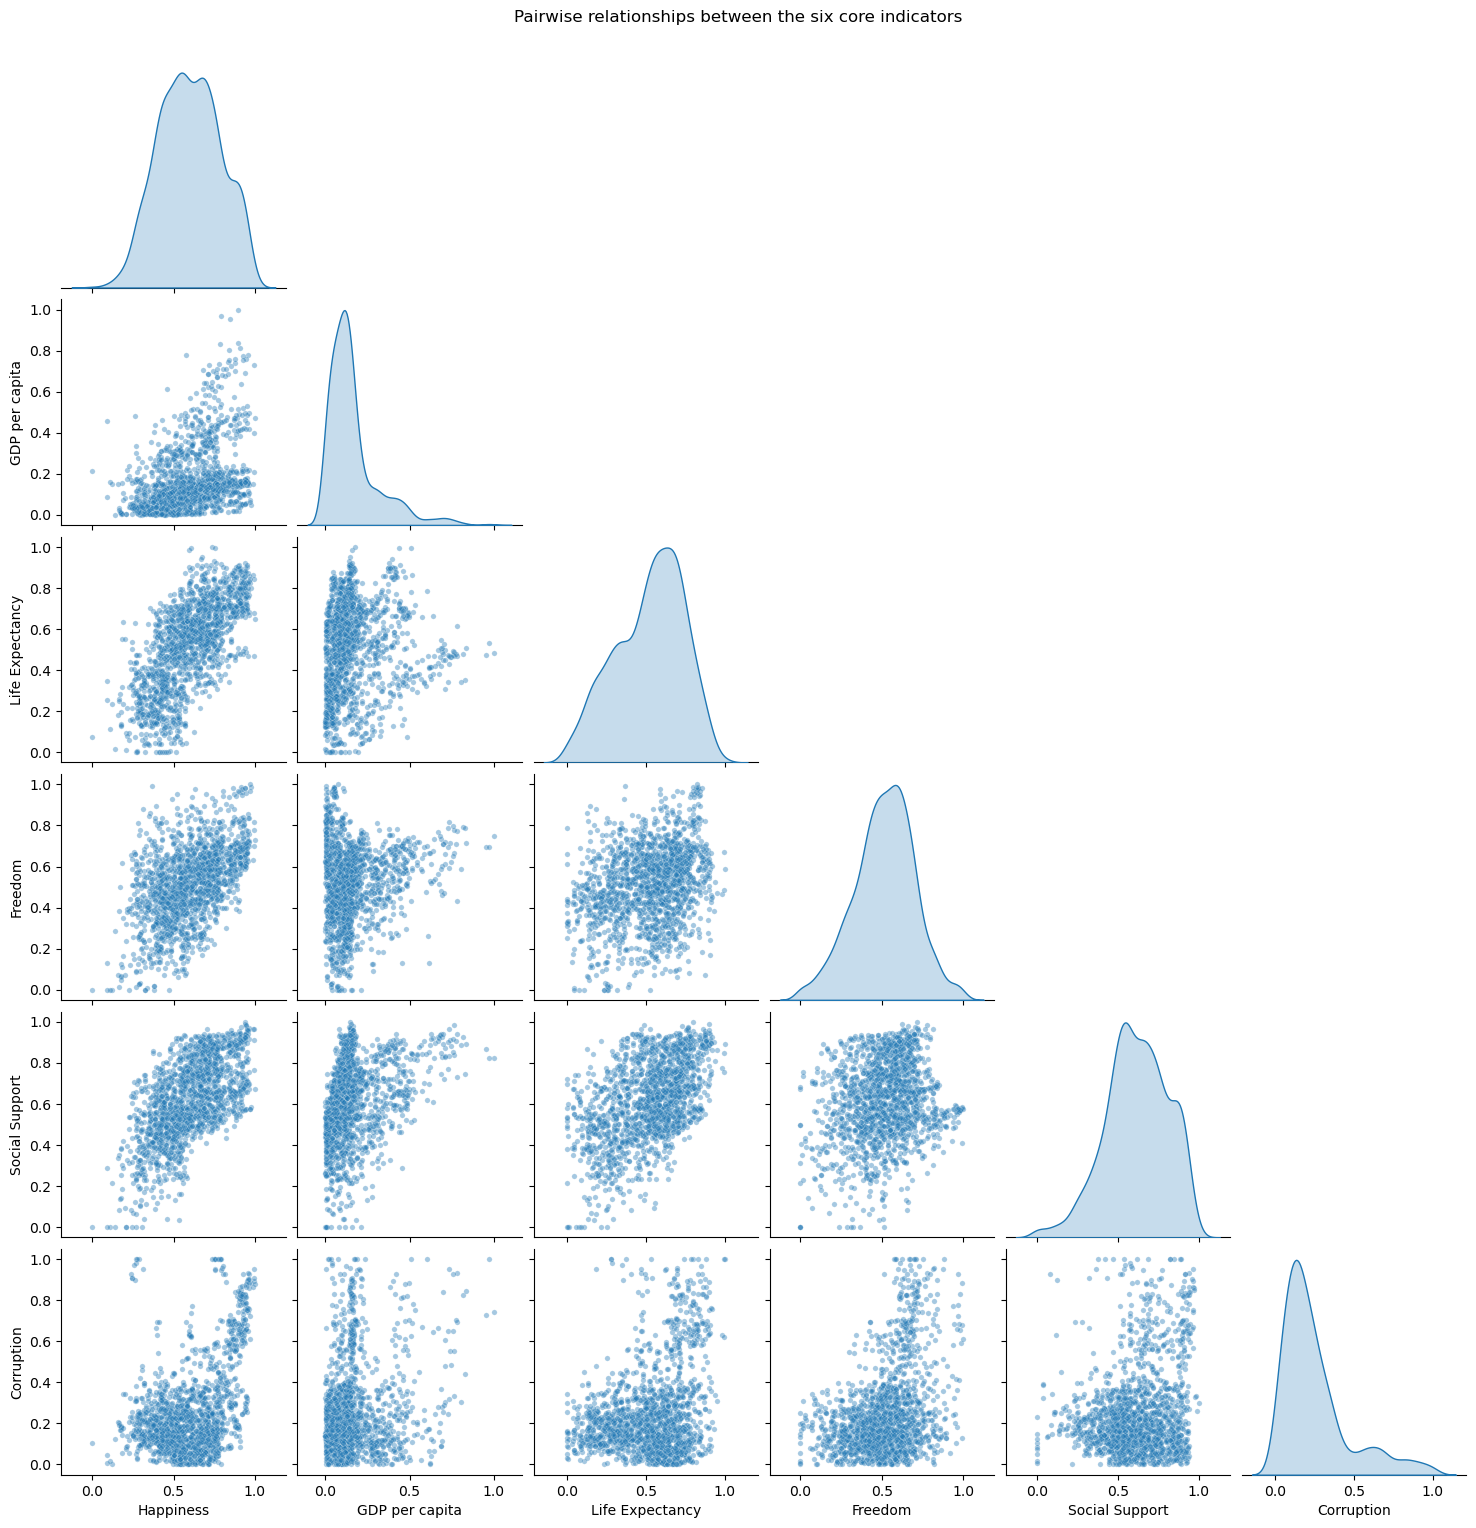

In [33]:
# Cell 29 - Pairplot
g = sns.pairplot(
    df_minmax[SCALE_COLS],
    diag_kind="kde",
    plot_kws={"alpha": 0.4, "s": 15},
    corner=True,
)
g.fig.suptitle("Pairwise relationships between the six core indicators", y=1.02)
g.fig.savefig(FIGURES_DIR / "pairplot.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(g.fig)

In [34]:
# ---------------------------------------------------------------
# Cell 30 - Pearson correlation with Happiness, by subregion
#
# Only subregions with n >= MIN_COUNTRIES_CORRELATION (15) are
# included. Smaller subregions have unstable Pearson r (a single
# outlier moves r by ±0.2), so they receive only descriptive
# statistics in the report.
# ---------------------------------------------------------------

n_by_subregion = (
    df_minmax.groupby("Subregion")["Country"]
    .nunique()
    .sort_values(ascending=False)
)

eligible = n_by_subregion[n_by_subregion >= MIN_COUNTRIES_CORRELATION].index.tolist()
excluded = n_by_subregion[n_by_subregion < MIN_COUNTRIES_CORRELATION].index.tolist()

print(f"Correlations for {len(eligible)} subregions (n>={MIN_COUNTRIES_CORRELATION}):")
for s in eligible:
    print(f"  {s:<40} n={n_by_subregion[s]}")
print(f"\nExcluded ({len(excluded)} subregions with n<{MIN_COUNTRIES_CORRELATION}):")
for s in excluded:
    print(f"  {s:<40} n={n_by_subregion[s]}")

regional_corr = (
    df_minmax[df_minmax["Subregion"].isin(eligible)]
    .groupby("Subregion")
    .apply(
        lambda g: g[SCALE_COLS].corr()["Happiness"].drop("Happiness"),
        include_groups=False,
    )
    .round(3)
)

print("\nPearson correlation with Happiness, per eligible subregion:")
print(regional_corr.to_string())

regional_corr.reset_index().to_latex(
    DOCS_DIR / "correlation_by_subregion.tex",
    index=False,
    caption=(
        f"Pearson correlation of each indicator with Happiness, computed "
        f"WITHIN each subregion with $n \\geq {MIN_COUNTRIES_CORRELATION}$ "
        f"countries. Subregions with fewer countries are excluded because "
        f"their estimates are unstable."
    ),
    label="tab:corr-subregion",
    float_format="%.3f",
)
print(f"\nExported: ./docs/tables/correlation_by_subregion.tex")

Correlations for 4 subregions (n>=15):
  Sub-Saharan Africa                       n=41
  Central and Eastern Europe               n=30
  Latin America and Caribbean              n=22
  Western Europe                           n=21

Excluded (7 subregions with n<15):
  Middle East                              n=13
  Southeast Asia                           n=9
  South Asia                               n=7
  East Asia                                n=6
  North Africa                             n=5
  Australia and New Zealand                n=2
  North America                            n=2

Pearson correlation with Happiness, per eligible subregion:
Happiness                    GDP per capita  Life Expectancy  Freedom  Social Support  Corruption
Subregion                                                                                        
Central and Eastern Europe            0.391           -0.020    0.389           0.498      -0.031
Latin America and Caribbean           0.094     

In [35]:
# ---------------------------------------------------------------
# Cell final - Reproducibility snapshot
#
# Writes Python version, platform, and pip freeze to
# docs/reproducibility/ for full environment reconstruction.
# ---------------------------------------------------------------

REPRO_DIR = DOCS_DIR.parent / "reproducibility"
REPRO_DIR.mkdir(parents=True, exist_ok=True)

with open(REPRO_DIR / "environment.txt", "w", encoding="utf-8") as f:
    f.write(f"Python: {sys.version}\n")
    f.write(f"Platform: {platform.platform()}\n\n")
    f.write(subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        capture_output=True, text=True,
    ).stdout)

subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    stdout=open(REPRO_DIR / "requirements.txt", "w", encoding="utf-8"),
)

print("Exported: ./docs/reproducibility/environment.txt")
print("Exported: ./docs/reproducibility/requirements.txt")

Exported: ./docs/reproducibility/environment.txt
Exported: ./docs/reproducibility/requirements.txt
